# Mislocalized Variant CP Feature Analyses

In [1]:
# imports
import os
import polars as pl
import pandas as pd
import numpy as np
from tqdm import tqdm
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import umap
from functools import reduce
import operator
from adjustText import adjust_text
import sys
sys.path.append("../../../../1_allele_collection/2_analysis")
from plot_utils import *
sys.path.append("../1_snakemake_pipeline/2025_varchamp_snakemake")
from img_utils import *

sns.set_style(style='white')
sns.set_context("notebook", font_scale=.9)

## 1. Loading data

### Read in the classifier metrics

In [2]:
mislocalized_var_cp_features = pl.read_csv("../../3_outputs/mislocalized_variants_key_cp_features.csv")
mislocalized_var_cp_features

Metadata_gene_allele,Metadata_Bio_Batch,Nuclei_RadialDistribution_RadialCV_GFP_3of10,Cytoplasm_RadialDistribution_RadialCV_GFP_1of10,Cytoplasm_RadialDistribution_MeanFrac_GFP_1of10,Nuclei_RadialDistribution_RadialCV_GFP_4of10,Nuclei_RadialDistribution_RadialCV_GFP_5of10,Cells_Correlation_RWC_GFP_Mito,Nuclei_Correlation_K_GFP_Mito,Cells_RadialDistribution_FracAtD_GFP_10of10,Cytoplasm_RadialDistribution_RadialCV_GFP_9of10,Cells_Correlation_Correlation_GFP_Mito,Cytoplasm_RadialDistribution_RadialCV_GFP_8of10,Cells_Intensity_MADIntensity_GFP,Cytoplasm_Correlation_Correlation_GFP_Mito,Nuclei_Correlation_Overlap_GFP_Mito,Cells_Texture_Correlation_GFP_5_00_256,Cells_Correlation_RWC_Mito_GFP,Cytoplasm_Granularity_1_GFP,Cells_Texture_InfoMeas1_GFP_10_02_256,Cytoplasm_Intensity_MaxIntensity_GFP,Cytoplasm_Texture_InverseDifferenceMoment_GFP_5_00_256,Nuclei_Granularity_4_GFP,Cytoplasm_Correlation_RWC_GFP_DNA,Nuclei_Correlation_RWC_DNA_GFP,Cells_RadialDistribution_MeanFrac_GFP_3of10,Cells_RadialDistribution_MeanFrac_GFP_1of10,Cells_Correlation_Correlation_AGP_GFP,Cells_Correlation_Correlation_DNA_GFP,Cytoplasm_RadialDistribution_RadialCV_GFP_10of10,Cells_RadialDistribution_RadialCV_GFP_10of10,Nuclei_Granularity_1_GFP,Cells_RadialDistribution_MeanFrac_GFP_10of10,Cytoplasm_Texture_AngularSecondMoment_GFP_5_00_256,Nuclei_Correlation_K_GFP_AGP,Nuclei_Correlation_Correlation_DNA_GFP,Cells_Texture_Correlation_GFP_20_01_256,…,Nuclei_Texture_AngularSecondMoment_GFP_5_00_256,Cells_RadialDistribution_MeanFrac_GFP_2of10,Cytoplasm_RadialDistribution_RadialCV_GFP_2of10,Cytoplasm_Texture_Correlation_GFP_10_01_256,Cells_Texture_Correlation_GFP_20_00_256,Cytoplasm_Granularity_3_GFP,Cytoplasm_RadialDistribution_MeanFrac_GFP_6of10,Cells_Texture_InfoMeas1_GFP_10_00_256,Cytoplasm_RadialDistribution_RadialCV_GFP_3of10,Nuclei_Texture_SumAverage_GFP_20_00_256,Cells_Texture_Correlation_GFP_20_03_256,Cells_Texture_Correlation_GFP_10_02_256,Cytoplasm_Texture_Correlation_GFP_5_02_256,Cytoplasm_Texture_Correlation_GFP_10_00_256,Cytoplasm_Texture_Correlation_GFP_5_01_256,Cells_Texture_Correlation_GFP_5_02_256,Cytoplasm_Texture_Correlation_GFP_5_03_256,Cytoplasm_Texture_Correlation_GFP_20_01_256,Cytoplasm_RadialDistribution_MeanFrac_GFP_10of10,Cytoplasm_Texture_InfoMeas2_GFP_20_02_256,Cytoplasm_Texture_AngularSecondMoment_GFP_20_00_256,Cytoplasm_Texture_InfoMeas1_GFP_20_03_256,Cytoplasm_Texture_Entropy_GFP_10_01_256,Cytoplasm_Texture_Entropy_GFP_10_00_256,Cells_Correlation_RWC_AGP_GFP,Cells_Texture_InfoMeas1_GFP_20_00_256,Cells_Texture_InfoMeas1_GFP_20_02_256,Cytoplasm_Texture_InverseDifferenceMoment_GFP_20_01_256,Cytoplasm_Texture_AngularSecondMoment_GFP_20_01_256,Cells_Granularity_4_GFP,Cytoplasm_Texture_InfoMeas1_GFP_20_02_256,Cells_Texture_InfoMeas1_GFP_20_03_256,Cells_Texture_Correlation_GFP_5_01_256,Nuclei_Texture_Correlation_GFP_5_03_256,Cytoplasm_Texture_Correlation_GFP_10_02_256,Cells_Texture_InfoMeas1_GFP_20_01_256,Cytoplasm_Texture_InfoMeas1_GFP_20_01_256
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""NT5C3A_Gly202Arg""","""B16A""",0.9760678,2.2093673,-0.716503,1.1730723,1.1924653,0.7716507,0.1761221,-0.785894,1.2728028,2.323934,1.8233386,0.064702,2.2547312,0.742358,-0.033019,0.2393,-0.11489,-0.086946,0.193477,-0.393849,0.8574591,-0.54341,-0.267042,0.5231664,0.015209,-0.303303,-0.4496,0.635494,0.269636,-0.039642,-0.852177,-0.174168,0.17037,-1.247851,-0.545782,…,0.4679295,0.288213,2.537152,0.269288,-0.155404,4.5210056,0.185844,-0.038065,2.1536493,0.0989269,-0.598233,-0.04124,0.248262,0.312586,0.211411,-0.059491,0.270633,-0.717581,-0.568877,0.473411,-0.11723,-0.514525,0.5422977,0.527832,-0.686346,-0.072446,-0.097091,-0.242505,-0.119322,1.7743028,-0.434775,-0.165741,-0.096142,-0.145851,0.284069,-0.105698,-0.5120

In [4]:
## Process mislocalized_var_cp_features for robust clustering analysis
# Step 1: Get the gene from "gene_allele" column by split by "_" and get the first element
mislocalized_var_cp_features_processed = mislocalized_var_cp_features.with_columns(
    pl.col("Metadata_gene_allele").str.split("_").list.get(0).alias("Gene")
)
# Step 2: Group the rows by Gene and Metadata_Bio_Batch and subtract all the numeric features 
# from the row with Gene == "IMPDH1" (with no "_aaXXXaa" variant) in all rows of variants
# First, let's identify the reference genes (those without "_" in gene_allele)
reference_genes = mislocalized_var_cp_features_processed.filter(
    ~pl.col("Metadata_gene_allele").str.contains("_")
).select("Gene").unique().to_series().to_list()

print(f"Reference genes found: {reference_genes}")
# Get numeric columns (excluding metadata columns)
numeric_cols = [col for col in mislocalized_var_cp_features_processed.columns 
                if not col.startswith("Metadata_") and not col in ["Gene"]]
print(f"Number of numeric features: {len(numeric_cols)}")

# Create a dictionary to store reference gene profiles for each batch
reference_profiles = {}
# For each gene and batch combination, get the reference profile
for gene in reference_genes:
    for batch in mislocalized_var_cp_features_processed["Metadata_Bio_Batch"].unique():
        ref_profile = mislocalized_var_cp_features_processed.filter(
            (pl.col("Gene") == gene) & 
            (pl.col("Metadata_Bio_Batch") == batch) &
            (~pl.col("Metadata_gene_allele").str.contains("_"))
        )
        if ref_profile.height > 0:
            ref_values = ref_profile.select(numeric_cols).row(0)
            reference_profiles[(gene, batch)] = ref_values

print(f"Reference profiles created for {len(reference_profiles)} gene-batch combinations")
# Step 3: Subtract reference gene features from variant features
variant_profiles = mislocalized_var_cp_features_processed.filter(
    pl.col("Metadata_gene_allele").str.contains("_")
)

# Create a new dataframe with subtracted features
subtracted_features = []
for row in variant_profiles.iter_rows(named=True):
    gene = row["Gene"]
    batch = row["Metadata_Bio_Batch"]
    
    if (gene, batch) in reference_profiles:
        ref_values = reference_profiles[(gene, batch)]
        # Subtract reference values from variant values
        subtracted_row = {"Metadata_gene_allele": row["Metadata_gene_allele"], "Gene": gene, "Metadata_Bio_Batch": batch}
        for i, col in enumerate(numeric_cols):
            try:
                variant_val = row[col]
                ref_val = ref_values[i]
                if variant_val is not None and ref_val is not None:
                    subtracted_row[col] = variant_val - ref_val
                else:
                    subtracted_row[col] = None
            except (IndexError, TypeError):
                subtracted_row[col] = None
        subtracted_features.append(subtracted_row)

subtracted_df = pl.DataFrame(subtracted_features)
print(f"Created subtracted features dataframe with shape: {subtracted_df.shape}")

# Step 4: Merge the gene_allele from different Metadata_Bio_Batch by taking the median of the features
merged_features = subtracted_df.group_by("Metadata_gene_allele").agg(
    pl.col(col).median().alias(col) for col in numeric_cols
).drop_nulls()

print(f"Merged features dataframe shape: {merged_features.shape}")
merged_features

Reference genes found: ['ZC4H2', 'PMP22', 'TTPA', 'RAD51D', 'GATA2', 'DES', 'FBP1', 'LIG4', 'FOXP3', 'PRPS1', 'FXN', 'BRAF', 'TPM3', 'KCNJ2', 'KCTD1', 'NR0B1', 'PYGL', 'LITAF', 'MSRB3', 'IL10', 'CDKN1A', 'APOA1', 'FLCN', 'FANCC', 'LMNA', 'RET', 'IMPDH1', 'COMP', 'STXBP1', 'AP2S1', 'PHYH', 'IL2RG', 'TAT', 'CTCF', 'NT5C3A', 'CTH', 'CCBE1', 'MLH1', 'SOS2', 'BFSP2', 'IL36RN', 'F9', 'RHO', 'HPRT1', 'SMAD3', 'EMD', 'MVK', 'SFTPA2', 'GFAP', 'KCTD7', 'BRCA1', 'FKBP6', 'AGXT', 'RP2', 'FH', 'TMEM43', 'KRAS', 'PNPO', 'SMAD1', 'TPM1', 'KRT8', 'KRT4', 'SFTPC', 'RPS19', 'GALE', 'HBD', 'BAG3', 'RAF1', 'AIPL1', 'BRIP1', 'SHOC2', 'SDHD', 'PNKP', 'COQ8A', 'DCX', 'SMARCB1']
Number of numeric features: 151
Reference profiles created for 165 gene-batch combinations
Created subtracted features dataframe with shape: (647, 154)
Merged features dataframe shape: (320, 152)


Metadata_gene_allele,Nuclei_RadialDistribution_RadialCV_GFP_3of10,Cytoplasm_RadialDistribution_RadialCV_GFP_1of10,Cytoplasm_RadialDistribution_MeanFrac_GFP_1of10,Nuclei_RadialDistribution_RadialCV_GFP_4of10,Nuclei_RadialDistribution_RadialCV_GFP_5of10,Cells_Correlation_RWC_GFP_Mito,Nuclei_Correlation_K_GFP_Mito,Cells_RadialDistribution_FracAtD_GFP_10of10,Cytoplasm_RadialDistribution_RadialCV_GFP_9of10,Cells_Correlation_Correlation_GFP_Mito,Cytoplasm_RadialDistribution_RadialCV_GFP_8of10,Cells_Intensity_MADIntensity_GFP,Cytoplasm_Correlation_Correlation_GFP_Mito,Nuclei_Correlation_Overlap_GFP_Mito,Cells_Texture_Correlation_GFP_5_00_256,Cells_Correlation_RWC_Mito_GFP,Cytoplasm_Granularity_1_GFP,Cells_Texture_InfoMeas1_GFP_10_02_256,Cytoplasm_Intensity_MaxIntensity_GFP,Cytoplasm_Texture_InverseDifferenceMoment_GFP_5_00_256,Nuclei_Granularity_4_GFP,Cytoplasm_Correlation_RWC_GFP_DNA,Nuclei_Correlation_RWC_DNA_GFP,Cells_RadialDistribution_MeanFrac_GFP_3of10,Cells_RadialDistribution_MeanFrac_GFP_1of10,Cells_Correlation_Correlation_AGP_GFP,Cells_Correlation_Correlation_DNA_GFP,Cytoplasm_RadialDistribution_RadialCV_GFP_10of10,Cells_RadialDistribution_RadialCV_GFP_10of10,Nuclei_Granularity_1_GFP,Cells_RadialDistribution_MeanFrac_GFP_10of10,Cytoplasm_Texture_AngularSecondMoment_GFP_5_00_256,Nuclei_Correlation_K_GFP_AGP,Nuclei_Correlation_Correlation_DNA_GFP,Cells_Texture_Correlation_GFP_20_01_256,Cytoplasm_Correlation_RWC_AGP_GFP,…,Nuclei_Texture_AngularSecondMoment_GFP_5_00_256,Cells_RadialDistribution_MeanFrac_GFP_2of10,Cytoplasm_RadialDistribution_RadialCV_GFP_2of10,Cytoplasm_Texture_Correlation_GFP_10_01_256,Cells_Texture_Correlation_GFP_20_00_256,Cytoplasm_Granularity_3_GFP,Cytoplasm_RadialDistribution_MeanFrac_GFP_6of10,Cells_Texture_InfoMeas1_GFP_10_00_256,Cytoplasm_RadialDistribution_RadialCV_GFP_3of10,Nuclei_Texture_SumAverage_GFP_20_00_256,Cells_Texture_Correlation_GFP_20_03_256,Cells_Texture_Correlation_GFP_10_02_256,Cytoplasm_Texture_Correlation_GFP_5_02_256,Cytoplasm_Texture_Correlation_GFP_10_00_256,Cytoplasm_Texture_Correlation_GFP_5_01_256,Cells_Texture_Correlation_GFP_5_02_256,Cytoplasm_Texture_Correlation_GFP_5_03_256,Cytoplasm_Texture_Correlation_GFP_20_01_256,Cytoplasm_RadialDistribution_MeanFrac_GFP_10of10,Cytoplasm_Texture_InfoMeas2_GFP_20_02_256,Cytoplasm_Texture_AngularSecondMoment_GFP_20_00_256,Cytoplasm_Texture_InfoMeas1_GFP_20_03_256,Cytoplasm_Texture_Entropy_GFP_10_01_256,Cytoplasm_Texture_Entropy_GFP_10_00_256,Cells_Correlation_RWC_AGP_GFP,Cells_Texture_InfoMeas1_GFP_20_00_256,Cells_Texture_InfoMeas1_GFP_20_02_256,Cytoplasm_Texture_InverseDifferenceMoment_GFP_20_01_256,Cytoplasm_Texture_AngularSecondMoment_GFP_20_01_256,Cells_Granularity_4_GFP,Cytoplasm_Texture_InfoMeas1_GFP_20_02_256,Cells_Texture_InfoMeas1_GFP_20_03_256,Cells_Texture_Correlation_GFP_5_01_256,Nuclei_Texture_Correlation_GFP_5_03_256,Cytoplasm_Texture_Correlation_GFP_10_02_256,Cells_Texture_InfoMeas1_GFP_20_01_256,Cytoplasm_Texture_InfoMeas1_GFP_20_01_256
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""SMAD3_Val410Phe""",0.417882,0.038779,0.072282,0.370605,0.327061,0.644707,-0.035328,-0.562281,-0.195287,-0.501549,-0.203137,-1.421758,-0.246213,-0.948955,0.061254,-0.584262,0.351662,0.201373,-0.193963,0.621345,2.219508,-0.082794,0.000253,0.884207,0.799018,-0.636189,0.625946,-0.113735,-0.356691,0.064041,-0.71751,0.67235,-0.108622,0.6421938,-0.392284,-0.304275,…,-0.208066,0.863425,-0.073591,-0.788559,-0.289393,0.241428,-0.09294,0.008213,-0.107308,0.120428,-0.454073,-0.06615,-0.726671,-0.634085,-0.682162,0.015981,-0.666054,0.086274,0.24746,-1.163815,0.584489,1.446174,-0.777741,-0.811673,-0.734195,0.536214,0.644645,0.576891,0.527473,2.2663327,1.493822,0.700119,-0.003007,-0.117308,-0.688397,0.739573,1.5

In [12]:
merged_features.mean().transpose().drop_nulls().to_pandas()["column_0"]

0      -0.055787649205937484
1        -0.1273800238020625
2        0.01758303726787499
3       -0.04809067674124999
4       -0.06099011879792184
               ...          
146     -0.06646293385203124
147      0.08093485973140621
148    -0.023181823703174998
149      0.30123816912031254
150       0.3799048726329688
Name: column_0, Length: 151, dtype: object

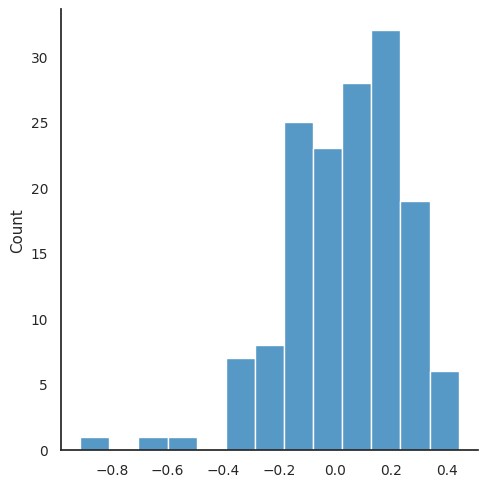

In [15]:
sns.displot(
    data=merged_features.mean().transpose().cast(pl.Float64).drop_nulls().to_pandas()["column_0"].values
)
plt.show()

Final features dataframe shape after removing NaN: (320, 151)

=== Hierarchical Clustering Analysis ===
Clusters: 2, Silhouette Score: 0.2052, Calinski-Harabasz Score: 81.86
Clusters: 3, Silhouette Score: 0.1851, Calinski-Harabasz Score: 62.62
Clusters: 4, Silhouette Score: 0.2010, Calinski-Harabasz Score: 56.86
Clusters: 5, Silhouette Score: 0.2098, Calinski-Harabasz Score: 51.51
Clusters: 6, Silhouette Score: 0.2062, Calinski-Harabasz Score: 48.19
Clusters: 7, Silhouette Score: 0.2205, Calinski-Harabasz Score: 46.08
Clusters: 8, Silhouette Score: 0.2328, Calinski-Harabasz Score: 44.58
Clusters: 9, Silhouette Score: 0.2104, Calinski-Harabasz Score: 42.65
Clusters: 10, Silhouette Score: 0.1831, Calinski-Harabasz Score: 41.09
Optimal number of clusters (Hierarchical): 8

=== K-Means Clustering Analysis ===
Clusters: 2, Silhouette Score: 0.2222, Calinski-Harabasz Score: 89.65
Clusters: 3, Silhouette Score: 0.2002, Calinski-Harabasz Score: 68.24
Clusters: 4, Silhouette Score: 0.2128, Cali

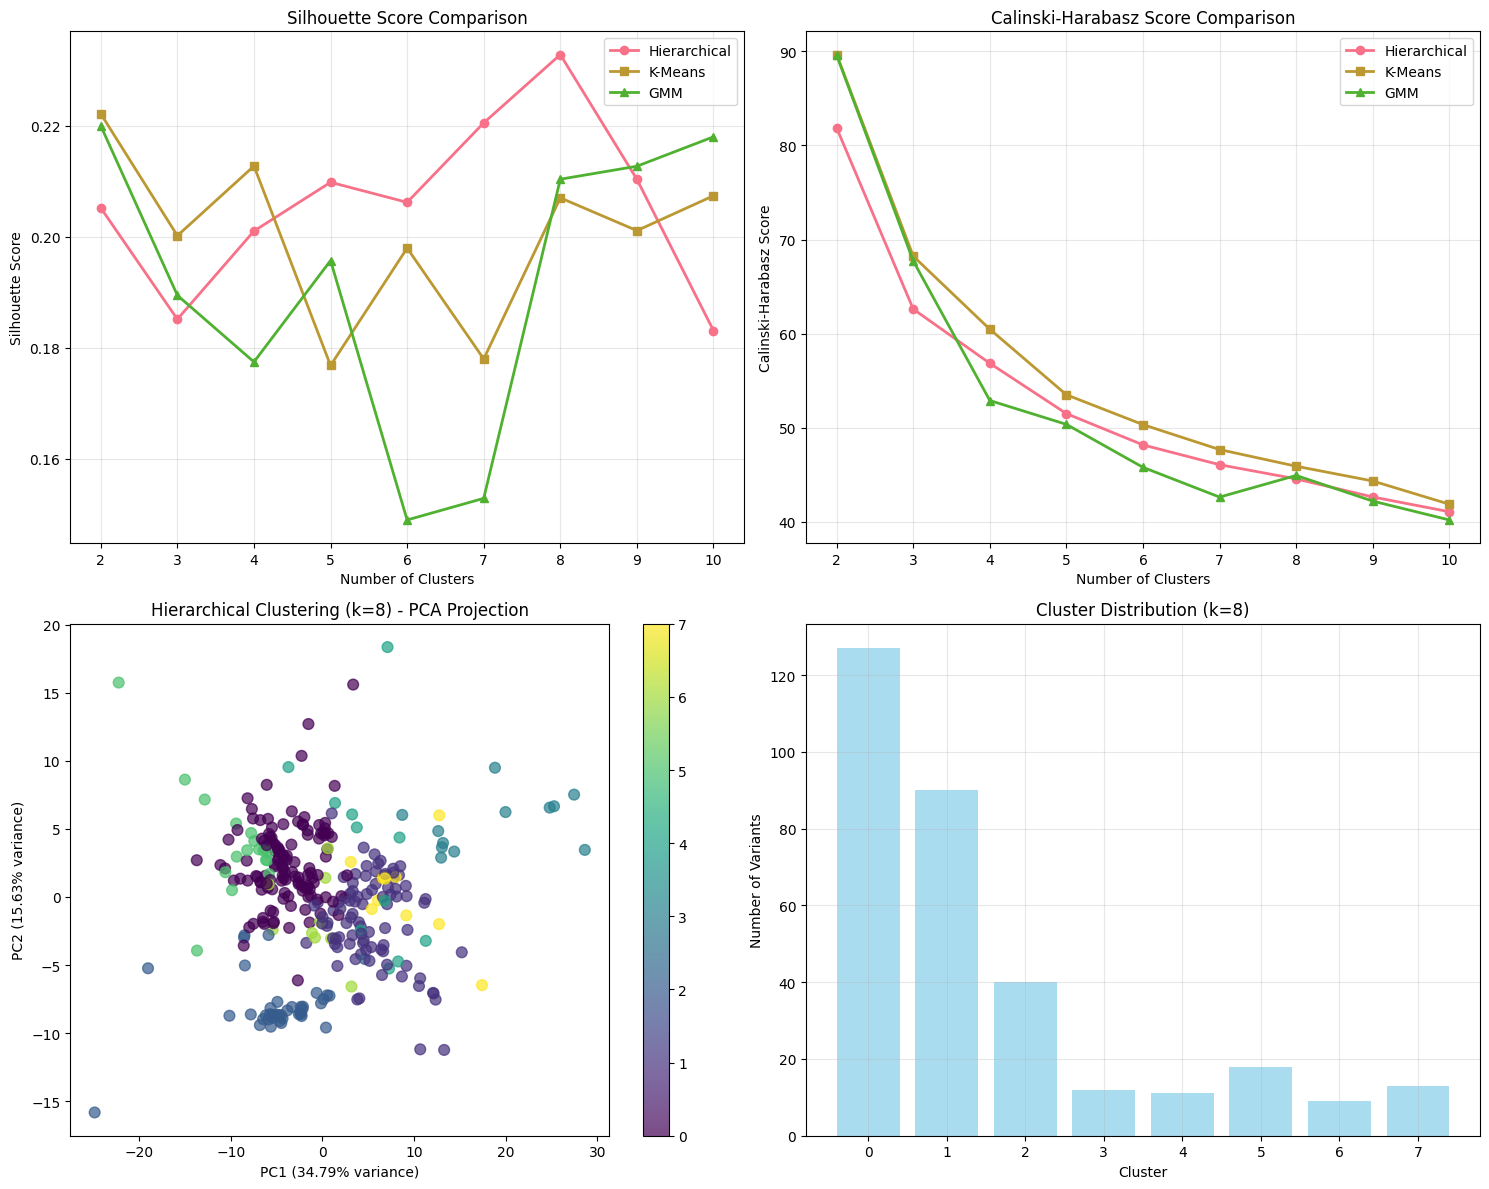


=== Final Clustering Results (k=8) ===
         Gene                                                   
        count                                             unique
Cluster                                                         
0         127  [STXBP1, KCTD1, MLH1, COQ8A, ZC4H2, KCTD7, KRA...
1          90  [SMAD3, BAG3, FBP1, FH, LIG4, TAT, LITAF, BRAF...
2          40     [KCNJ2, KRT8, BFSP2, EMD, SMAD3, IMPDH1, GFAP]
3          12                    [DES, KRT4, NT5C3A, PNPO, GFAP]
4          11                  [NR0B1, SMAD3, LMNA, CTCF, RPS19]
5          18                [RAD51D, ZC4H2, SOS2, SHOC2, GATA2]
6           9                           [PMP22, RHO, RP2, IL2RG]
7          13  [BRCA1, FXN, STXBP1, FOXP3, RAD51D, SMAD1, IL3...

Cluster 0 (127 variants):
  - STXBP1_Gly417Asp
  - KCTD1_Val248Ile
  - MLH1_Cys39Phe
  - MLH1_Gln701His
  - STXBP1_Met443Arg
  - COQ8A_Gly549Ser
  - ZC4H2_Ile7Val
  - KCTD7_Asn273Ile
  - KRAS_Ile36Met
  - F9_Tyr161Cys
  - MLH1_Ile36Asn
  - MLH1

In [31]:
# Convert to pandas for clustering
merged_features_pd = merged_features.to_pandas().set_index("Metadata_gene_allele")

# Remove any remaining NaN values
merged_features_pd = merged_features_pd.dropna()

print(f"Final features dataframe shape after removing NaN: {merged_features_pd.shape}")

# Step 5: Perform robust clustering methods using scipy and scikit-learn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import pdist
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Standardize the features
scaler = StandardScaler()
features_scaled = scaler.fit_transform(merged_features_pd)

# Method 1: Hierarchical Clustering (Agglomerative)
print("\n=== Hierarchical Clustering Analysis ===")

# Try different numbers of clusters
silhouette_scores_hier = []
calinski_scores_hier = []
cluster_range = range(2, min(11, len(merged_features_pd) // 2))

for k in cluster_range:
    if k < len(merged_features_pd):
        clustering = AgglomerativeClustering(n_clusters=k, linkage='ward')
        labels = clustering.fit_predict(features_scaled)
        
        if len(np.unique(labels)) > 1:
            sil_score = silhouette_score(features_scaled, labels)
            cal_score = calinski_harabasz_score(features_scaled, labels)
        else:
            sil_score = 0
            cal_score = 0
            
        silhouette_scores_hier.append(sil_score)
        calinski_scores_hier.append(cal_score)
        print(f"Clusters: {k}, Silhouette Score: {sil_score:.4f}, Calinski-Harabasz Score: {cal_score:.2f}")

# Find optimal number of clusters
optimal_k_hier = cluster_range[np.argmax(silhouette_scores_hier)]
print(f"Optimal number of clusters (Hierarchical): {optimal_k_hier}")

# Method 2: K-Means Clustering
print("\n=== K-Means Clustering Analysis ===")

silhouette_scores_kmeans = []
calinski_scores_kmeans = []

for k in cluster_range:
    if k < len(merged_features_pd):
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = kmeans.fit_predict(features_scaled)
        
        if len(np.unique(labels)) > 1:
            sil_score = silhouette_score(features_scaled, labels)
            cal_score = calinski_harabasz_score(features_scaled, labels)
        else:
            sil_score = 0
            cal_score = 0
            
        silhouette_scores_kmeans.append(sil_score)
        calinski_scores_kmeans.append(cal_score)
        print(f"Clusters: {k}, Silhouette Score: {sil_score:.4f}, Calinski-Harabasz Score: {cal_score:.2f}")

optimal_k_kmeans = cluster_range[np.argmax(silhouette_scores_kmeans)]
print(f"Optimal number of clusters (K-Means): {optimal_k_kmeans}")

# Method 3: Gaussian Mixture Model
print("\n=== Gaussian Mixture Model Analysis ===")

silhouette_scores_gmm = []
calinski_scores_gmm = []

for k in cluster_range:
    if k < len(merged_features_pd):
        gmm = GaussianMixture(n_components=k, random_state=42)
        labels = gmm.fit_predict(features_scaled)
        
        if len(np.unique(labels)) > 1:
            sil_score = silhouette_score(features_scaled, labels)
            cal_score = calinski_harabasz_score(features_scaled, labels)
        else:
            sil_score = 0
            cal_score = 0
            
        silhouette_scores_gmm.append(sil_score)
        calinski_scores_gmm.append(cal_score)
        print(f"Clusters: {k}, Silhouette Score: {sil_score:.4f}, Calinski-Harabasz Score: {cal_score:.2f}")

optimal_k_gmm = cluster_range[np.argmax(silhouette_scores_gmm)]
print(f"Optimal number of clusters (GMM): {optimal_k_gmm}")

# Method 4: DBSCAN (density-based)
print("\n=== DBSCAN Clustering Analysis ===")

# Try different eps values
eps_values = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0]
best_dbscan_score = -1
best_dbscan_params = None

for eps in eps_values:
    dbscan = DBSCAN(eps=eps, min_samples=3)
    labels = dbscan.fit_predict(features_scaled)
    
    if len(np.unique(labels)) > 1 and -1 not in labels:  # No noise points
        sil_score = silhouette_score(features_scaled, labels)
        cal_score = calinski_harabasz_score(features_scaled, labels)
        
        if sil_score > best_dbscan_score:
            best_dbscan_score = sil_score
            best_dbscan_params = (eps, len(np.unique(labels)))
        
        print(f"DBSCAN eps={eps}, clusters={len(np.unique(labels))}, Silhouette Score: {sil_score:.4f}")

if best_dbscan_params:
    print(f"Best DBSCAN: eps={best_dbscan_params[0]}, clusters={best_dbscan_params[1]}")

# Visualize clustering results
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# Plot silhouette scores comparison
axes[0, 0].plot(list(cluster_range), silhouette_scores_hier, 'o-', label='Hierarchical', linewidth=2)
axes[0, 0].plot(list(cluster_range), silhouette_scores_kmeans, 's-', label='K-Means', linewidth=2)
axes[0, 0].plot(list(cluster_range), silhouette_scores_gmm, '^-', label='GMM', linewidth=2)
axes[0, 0].set_xlabel('Number of Clusters')
axes[0, 0].set_ylabel('Silhouette Score')
axes[0, 0].set_title('Silhouette Score Comparison')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Plot Calinski-Harabasz scores comparison
axes[0, 1].plot(list(cluster_range), calinski_scores_hier, 'o-', label='Hierarchical', linewidth=2)
axes[0, 1].plot(list(cluster_range), calinski_scores_kmeans, 's-', label='K-Means', linewidth=2)
axes[0, 1].plot(list(cluster_range), calinski_scores_gmm, '^-', label='GMM', linewidth=2)
axes[0, 1].set_xlabel('Number of Clusters')
axes[0, 1].set_ylabel('Calinski-Harabasz Score')
axes[0, 1].set_title('Calinski-Harabasz Score Comparison')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Perform PCA for visualization
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
features_pca = pca.fit_transform(features_scaled)

# Apply best clustering method (using hierarchical as default)
best_clustering = AgglomerativeClustering(n_clusters=optimal_k_hier, linkage='ward')
cluster_labels = best_clustering.fit_predict(features_scaled)

# Plot PCA with clusters
scatter = axes[1, 0].scatter(features_pca[:, 0], features_pca[:, 1], c=cluster_labels, 
                           cmap='viridis', alpha=0.7, s=60)
axes[1, 0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%} variance)')
axes[1, 0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%} variance)')
axes[1, 0].set_title(f'Hierarchical Clustering (k={optimal_k_hier}) - PCA Projection')
plt.colorbar(scatter, ax=axes[1, 0])

# Plot cluster distribution
cluster_counts = np.bincount(cluster_labels)
axes[1, 1].bar(range(len(cluster_counts)), cluster_counts, alpha=0.7, color='skyblue')
axes[1, 1].set_xlabel('Cluster')
axes[1, 1].set_ylabel('Number of Variants')
axes[1, 1].set_title(f'Cluster Distribution (k={optimal_k_hier})')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Create final clustering results dataframe
clustering_results = pd.DataFrame(features_scaled, index=merged_features_pd.index, columns=merged_features_pd.columns)
clustering_results['Cluster'] = cluster_labels
clustering_results['Gene'] = clustering_results.index.str.split('_').str[0]
clustering_results['Gene_allele'] = clustering_results.index


# Show cluster assignments
print(f"\n=== Final Clustering Results (k={optimal_k_hier}) ===")
cluster_summary = clustering_results.groupby('Cluster').agg({
    'Gene': ['count', 'unique']
}).round(2)
print(cluster_summary)

# Show variants in each cluster
for cluster_id in sorted(clustering_results['Cluster'].unique()):
    cluster_variants = clustering_results[clustering_results['Cluster'] == cluster_id]
    print(f"\nCluster {cluster_id} ({len(cluster_variants)} variants):")
    for variant in cluster_variants.index:
        print(f"  - {variant}")

# Save results
clustering_results.to_csv("mislocalized_variants_clustering_results.csv")
print(f"\nClustering results saved to 'mislocalized_variants_clustering_results.csv'")

/home/shenrunx/software/anaconda3/envs/varchamp/lib/python3.8/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


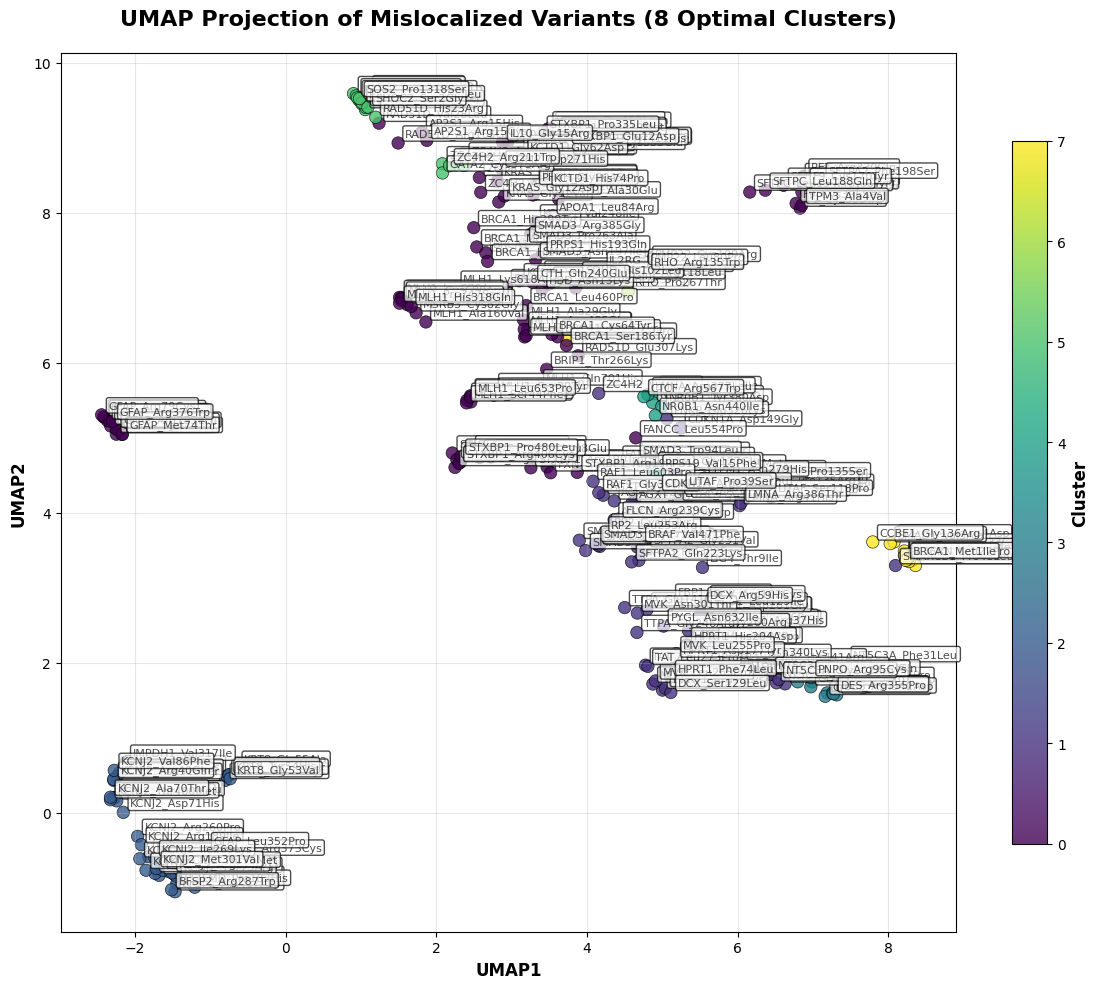


=== UMAP Cluster Summary ===
Cluster 0: 127 samples
  Genes: AP2S1, APOA1, BRCA1, BRIP1, COMP, COQ8A, CTH, F9, FANCC, FKBP6, FXN, GALE, GFAP, HBD, IL10, IL36RN, IMPDH1, KCNJ2, KCTD1, KCTD7, KRAS, MLH1, MSRB3, MVK, PHYH, PRPS1, RAD51D, RET, SFTPA2, SFTPC, SMAD3, STXBP1, TPM1, TPM3, ZC4H2
  UMAP coordinates range: X(-2.44, 7.11), Y(4.53, 9.19)

Cluster 1: 90 samples
  Genes: AGXT, AIPL1, BAG3, BRAF, CDKN1A, COMP, COQ8A, DCX, F9, FBP1, FH, FLCN, HPRT1, KCTD7, LIG4, LITAF, LMNA, MVK, NR0B1, NT5C3A, PNKP, PRPS1, PYGL, RAF1, RP2, SDHD, SFTPA2, SMAD3, SMARCB1, TAT, TMEM43, TPM1, TTPA, ZC4H2
  UMAP coordinates range: X(3.88, 8.09), Y(1.60, 7.11)

Cluster 2: 40 samples
  Genes: BFSP2, EMD, GFAP, IMPDH1, KCNJ2, KRT8, SMAD3
  UMAP coordinates range: X(-2.33, -0.64), Y(-1.06, 0.67)

Cluster 3: 12 samples
  Genes: DES, GFAP, KRT4, NT5C3A, PNPO
  UMAP coordinates range: X(6.80, 7.44), Y(1.55, 1.99)

Cluster 4: 11 samples
  Genes: CTCF, LMNA, NR0B1, RPS19, SMAD3
  UMAP coordinates range: X(4.64, 4.9

In [33]:
# Create UMAP visualization using the optimal 8 clusters
import umap
from sklearn.preprocessing import StandardScaler

# Prepare data for UMAP
features_for_umap = clustering_results.drop(['Cluster', 'Gene', "Gene_allele"], axis=1, errors='ignore')

# Standardize features
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features_for_umap)

# Perform UMAP
umap_model = umap.UMAP(
    n_neighbors=15, 
    min_dist=0.1, 
    n_components=2, 
    random_state=42,
    metric='euclidean'
)
umap_result = umap_model.fit_transform(features_scaled)

# Create UMAP dataframe
umap_df = pd.DataFrame(umap_result, columns=["UMAP1", "UMAP2"], index=clustering_results.index)
umap_df['Cluster'] = clustering_results['Cluster']
umap_df['Gene'] = clustering_results['Gene']
umap_df['Gene_Allele'] = umap_df.index

# Create the UMAP plot
plt.figure(figsize=(12, 10))

# Create scatter plot with cluster colors
scatter = plt.scatter(umap_df['UMAP1'], umap_df['UMAP2'], 
                     c=umap_df['Cluster'], 
                     cmap='viridis', 
                     s=80, 
                     alpha=0.8, 
                     edgecolors='black', 
                     linewidth=0.5)

# Add sample labels (gene_allele names)
for idx, row in umap_df.iterrows():
    plt.annotate(row['Gene_Allele'], 
                (row['UMAP1'], row['UMAP2']), 
                xytext=(5, 5), 
                textcoords='offset points', 
                fontsize=8, 
                alpha=0.7,
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7))

# Customize the plot
plt.title("UMAP Projection of Mislocalized Variants (8 Optimal Clusters)", 
          fontsize=16, fontweight='bold', pad=20)
plt.xlabel("UMAP1", fontsize=12, fontweight='bold')
plt.ylabel("UMAP2", fontsize=12, fontweight='bold')

# Add colorbar
cbar = plt.colorbar(scatter, shrink=0.8)
cbar.set_label('Cluster', fontsize=12, fontweight='bold')
# cbar.set_ticks(range(1, len(unique_clusters) + 1))
# cbar.set_ticklabels([f'Cluster {i}' for i in range(1, len(unique_clusters) + 1)])

# Add grid
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print UMAP cluster information
print(f"\n=== UMAP Cluster Summary ===")
for cluster_id in sorted(umap_df['Cluster'].unique()):
    cluster_samples = umap_df[umap_df['Cluster'] == cluster_id]
    print(f"Cluster {cluster_id}: {len(cluster_samples)} samples")
    print(f"  Genes: {', '.join(sorted(cluster_samples['Gene'].unique()))}")
    print(f"  UMAP coordinates range: X({cluster_samples['UMAP1'].min():.2f}, {cluster_samples['UMAP1'].max():.2f}), "
          f"Y({cluster_samples['UMAP2'].min():.2f}, {cluster_samples['UMAP2'].max():.2f})")
    print()

<ipython-input-35-c27e378094f6>:52: UserWarning: Tight layout not applied. tight_layout cannot make axes height small enough to accommodate all axes decorations.
  plt.tight_layout()


<Figure size 2000x800 with 0 Axes>

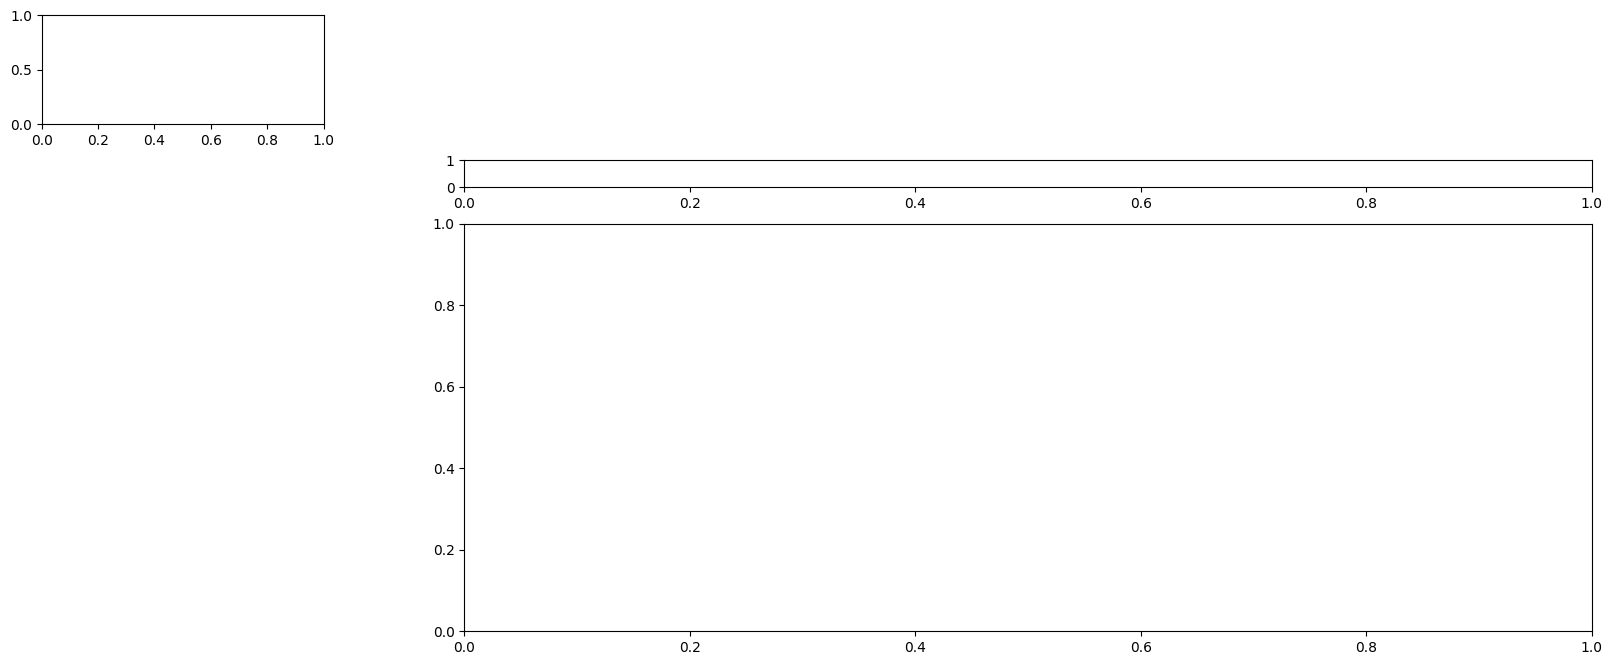

<Figure size 2000x800 with 0 Axes>

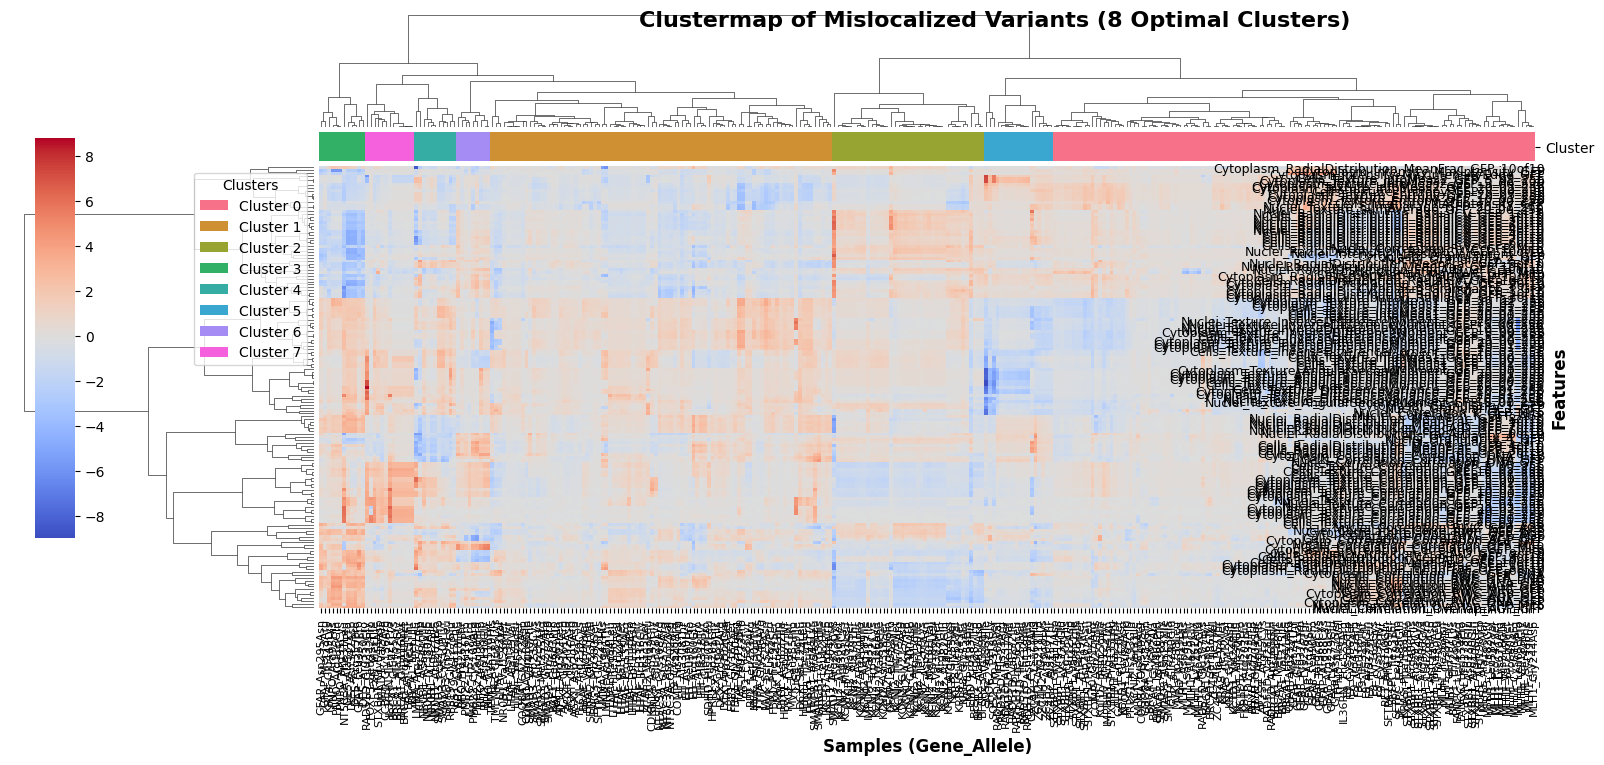


=== Clustermap Cluster Summary ===
Cluster 0: 127 samples
  Genes: AP2S1, APOA1, BRCA1, BRIP1, COMP, COQ8A, CTH, F9, FANCC, FKBP6, FXN, GALE, GFAP, HBD, IL10, IL36RN, IMPDH1, KCNJ2, KCTD1, KCTD7, KRAS, MLH1, MSRB3, MVK, PHYH, PRPS1, RAD51D, RET, SFTPA2, SFTPC, SMAD3, STXBP1, TPM1, TPM3, ZC4H2
  Sample names: STXBP1_Gly417Asp, KCTD1_Val248Ile, MLH1_Cys39Phe, MLH1_Gln701His, STXBP1_Met443Arg, COQ8A_Gly549Ser, ZC4H2_Ile7Val, KCTD7_Asn273Ile, KRAS_Ile36Met, F9_Tyr161Cys, MLH1_Ile36Asn, MLH1_Val185Gly, FKBP6_Arg202His, GFAP_Leu90Pro, BRCA1_Val275Ile, GFAP_Lys279Glu, KRAS_Gly12Val, F9_Cys335Tyr, STXBP1_Arg505His, F9_Cys335Trp, MVK_Pro288Leu, GALE_Leu313Met, IL10_Phe129Tyr, RET_Arg330Gln, MLH1_Pro640Ser, F9_Ile316Thr, STXBP1_Leu183Pro, MLH1_Leu582Val, MLH1_Ala160Val, STXBP1_Arg292Cys, KCTD1_Ala30Glu, IL36RN_Thr123Arg, STXBP1_Arg305Gln, STXBP1_Arg406Leu, RAD51D_Val28Leu, FXN_Trp173Gly, MSRB3_Cys82Gly, MLH1_Asp41His, ZC4H2_Ala162Thr, STXBP1_Leu256Pro, GFAP_Arg88Cys, BRCA1_Met548Ile, GFAP_Asn77

In [35]:
# Create clustermap using the optimal 8 clusters from hierarchical clustering
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Get the clustering results from the previous analysis
# Assuming clustering_results is available from the previous cell
if 'clustering_results' not in locals():
    # Load the saved clustering results if not in memory
    clustering_results = pd.read_csv("mislocalized_variants_clustering_results.csv", index_col=0)

# Prepare data for clustermap
features_for_clustermap = clustering_results.drop(['Cluster', 'Gene', "Gene_allele"], axis=1, errors='ignore')

# Create color mapping for clusters
unique_clusters = np.sort(clustering_results['Cluster'].unique())
palette = sns.color_palette("husl", len(unique_clusters))
cluster_colors = dict(zip(unique_clusters, palette))
row_colors = clustering_results['Cluster'].map(cluster_colors)

# Create the clustermap
plt.figure(figsize=(20, 8))
g = sns.clustermap(
    features_for_clustermap.T,  # Transpose to have samples as columns
    col_colors=row_colors,
    metric="euclidean",
    method="ward",
    cmap="coolwarm",
    cbar_pos=(0.02, 0.32, 0.02, 0.5),
    figsize=(20, 8),
    row_cluster=True,
    col_cluster=True,
    colors_ratio=0.05,
    xticklabels=True,
    yticklabels=True
)

# Customize the plot
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90, ha="center", fontsize=8)
plt.setp(g.ax_heatmap.get_yticklabels(), rotation=0, ha="right", fontsize=9)
g.ax_heatmap.set_xlabel("Samples (Gene_Allele)", fontsize=12, fontweight='bold')
g.ax_heatmap.set_ylabel("Features", fontsize=12, fontweight='bold')

# Add cluster legend
legend_elements = [plt.Rectangle((0,0),1,1, facecolor=cluster_colors[cluster], 
                                label=f'Cluster {cluster}') for cluster in unique_clusters]
g.ax_row_dendrogram.legend(handles=legend_elements, loc='upper right', 
                          title="Clusters", fontsize=10)

plt.suptitle("Clustermap of Mislocalized Variants (8 Optimal Clusters)", 
             y=0.98, fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Print cluster information
print(f"\n=== Clustermap Cluster Summary ===")
for cluster_id in sorted(unique_clusters):
    cluster_samples = clustering_results[clustering_results['Cluster'] == cluster_id]
    print(f"Cluster {cluster_id}: {len(cluster_samples)} samples")
    print(f"  Genes: {', '.join(sorted(cluster_samples['Gene'].unique()))}")
    print(f"  Sample names: {', '.join(cluster_samples.index.tolist())}")
    print()

In [28]:
features_for_clustermap.mean()

Nuclei_RadialDistribution_RadialCV_GFP_3of10      -0.055788
Cytoplasm_RadialDistribution_RadialCV_GFP_1of10   -0.127380
Cytoplasm_RadialDistribution_MeanFrac_GFP_1of10    0.017583
Nuclei_RadialDistribution_RadialCV_GFP_4of10      -0.048091
Nuclei_RadialDistribution_RadialCV_GFP_5of10      -0.060990
                                                     ...   
Cells_Texture_Correlation_GFP_5_01_256            -0.066463
Nuclei_Texture_Correlation_GFP_5_03_256            0.080935
Cytoplasm_Texture_Correlation_GFP_10_02_256       -0.023182
Cells_Texture_InfoMeas1_GFP_20_01_256              0.301238
Cytoplasm_Texture_InfoMeas1_GFP_20_01_256          0.379905
Length: 151, dtype: float64

### Read in cell profiles of mislocalized alleles

In [4]:
# Paths
profile_dir = "../1_snakemake_pipeline/2025_varchamp_snakemake/snakemake_pipeline/outputs/batch_profiles"
pass_qc_prof_dir = f"{profile_dir}/" + "{}/profiles_tcdropped_filtered_var_mad_outlier_featselect.parquet"

# Get meta features
b7_alleles = (
    pl.scan_parquet(
        pass_qc_prof_dir.format(batches[0])
    )
    .filter(pl.col("Metadata_gene_allele").is_in(all_alleles))
    .with_columns(
        pl.concat_str(
            [
                "Metadata_Plate",
                "Metadata_Well",
                "Metadata_ImageNumber",
                "Metadata_ObjectNumber",
            ],
            separator="_",
        ).alias("Metadata_CellID")
    )
    .select([
        "Metadata_CellID",
        "Metadata_gene_allele",
        "Metadata_Well",
        "Metadata_Plate",
    ])
)

b8_alleles = (
    pl.scan_parquet(
        pass_qc_prof_dir.format(batches[1])
    )
    .filter(pl.col("Metadata_gene_allele").is_in(all_alleles))
    .with_columns(
        pl.concat_str(
            [
                "Metadata_Plate",
                "Metadata_Well",
                "Metadata_ImageNumber",
                "Metadata_ObjectNumber",
            ],
            separator="_",
        ).alias("Metadata_CellID")
    )
    .select([
        "Metadata_CellID",
        "Metadata_gene_allele",
        "Metadata_Well",
        "Metadata_Plate",
    ])
)

cell_alleles = pl.concat([b7_alleles.collect(), b8_alleles.collect()])

In [5]:
prof_dir = "../1_snakemake_pipeline/2025_varchamp_snakemake/snakemake_pipeline/outputs/batch_profiles/{}/profiles.parquet"

b7_prof = pl.scan_parquet(
    prof_dir.format(batches[0])
).with_columns(
    pl.concat_str(
        [
            "Metadata_Plate",
            "Metadata_Well",
            "Metadata_ImageNumber",
            "Metadata_ObjectNumber",
        ],
        separator="_",
    ).alias("Metadata_CellID")
)
b8_prof = pl.scan_parquet(
    prof_dir.format(batches[1])
).with_columns(
    pl.concat_str(
        [
            "Metadata_Plate",
            "Metadata_Well",
            "Metadata_ImageNumber",
            "Metadata_ObjectNumber",
        ],
        separator="_",
    ).alias("Metadata_CellID")
)

gfp_int = [i for i in b7_prof.schema.keys() if "GFP" in i]
gfp_int = ["Metadata_CellID"] + gfp_int

profiles = pl.concat([
    b7_prof.select(gfp_int).collect(),
    b8_prof.select(gfp_int).collect(),
])

# This method of joining ensures that only cells past filters are included in the abundance analysis
profiles = cell_alleles.join(profiles, on="Metadata_CellID", how="left")

/tmp/ipykernel_355300/1976869560.py:30: PerformanceWarning: Resolving the schema of a LazyFrame is a potentially expensive operation. Use `LazyFrame.collect_schema()` to get the schema without this warning.
  gfp_int = [i for i in b7_prof.schema.keys() if "GFP" in i]


In [ ]:
profiles.select(pl.col([col for col in profiles.columns if "GFP" in col])).mean().transpose(include_header=True).sort(by="column_0")


column,column_0
str,f64
"""Nuclei_Correlation_Correlation…",-0.235305
"""Cytoplasm_Texture_InfoMeas1_GF…",-0.167482
"""Cytoplasm_Texture_InfoMeas1_GF…",-0.165063
"""Cells_Texture_InfoMeas1_GFP_5_…",-0.165022
"""Cells_Texture_InfoMeas1_GFP_5_…",-0.162067
…,…
"""Nuclei_Location_CenterMassInte…",542.003243
"""Cells_Location_CenterMassInten…",542.01289
"""Cytoplasm_Location_CenterMassI…",542.019832


In [ ]:
profiles.select(pl.col([col for col in profiles.columns if "GFP" in col])).mean().transpose(include_header=True).sort(by="column_0").filter(pl.col("column")=="Cytoplasm_Granularity_1_GFP")

column,column_0
str,f64
"""Cytoplasm_Granularity_1_GFP""",41.236345


In [18]:
profiles.select(pl.col([col for col in profiles.columns if "GFP" in col])).std().transpose(include_header=True).sort(by="column_0")

column,column_0
str,f64
"""Cytoplasm_Location_CenterMassI…",0.0
"""Cytoplasm_Location_MaxIntensit…",0.0
"""Cells_Location_CenterMassInten…",0.0
"""Cells_Location_MaxIntensity_Z_…",0.0
"""Nuclei_Location_CenterMassInte…",0.0
…,…
"""Cytoplasm_Texture_SumVariance_…",969.603224
"""Cells_Texture_SumVariance_GFP_…",1016.575164
"""Cells_Texture_SumVariance_GFP_…",1016.990332


In [19]:
profiles.select(pl.col([col for col in profiles.columns if "GFP" in col])).std().transpose(include_header=True).sort(by="column_0").filter(pl.col("column")=="Cytoplasm_Granularity_1_GFP")

column,column_0
str,f64
"""Cytoplasm_Granularity_1_GFP""",26.55536


### Aggregate to well profiles

In [6]:
well_profiles = (
    profiles.group_by(["Metadata_Plate", "Metadata_Well", "Metadata_gene_allele"])
    .agg(
        pl.col(col).median().alias(col)
        for col in profiles.columns
        if not col.startswith("Metadata_")
    )
    .unique()
    .drop_nulls("Metadata_gene_allele")
)
well_profiles

Metadata_Plate,Metadata_Well,Metadata_gene_allele,Cytoplasm_Correlation_Correlation_AGP_GFP,Cytoplasm_Correlation_Correlation_Brightfield_GFP,Cytoplasm_Correlation_Correlation_Brightfield_H_GFP,Cytoplasm_Correlation_Correlation_Brightfield_L_GFP,Cytoplasm_Correlation_Correlation_DNA_GFP,Cytoplasm_Correlation_Correlation_GFP_Mito,Cytoplasm_Correlation_Costes_AGP_GFP,Cytoplasm_Correlation_Costes_Brightfield_GFP,Cytoplasm_Correlation_Costes_Brightfield_H_GFP,Cytoplasm_Correlation_Costes_Brightfield_L_GFP,Cytoplasm_Correlation_Costes_DNA_GFP,Cytoplasm_Correlation_Costes_GFP_AGP,Cytoplasm_Correlation_Costes_GFP_Brightfield,Cytoplasm_Correlation_Costes_GFP_Brightfield_H,Cytoplasm_Correlation_Costes_GFP_Brightfield_L,Cytoplasm_Correlation_Costes_GFP_DNA,Cytoplasm_Correlation_Costes_GFP_Mito,Cytoplasm_Correlation_Costes_Mito_GFP,Cytoplasm_Correlation_K_AGP_GFP,Cytoplasm_Correlation_K_Brightfield_GFP,Cytoplasm_Correlation_K_Brightfield_H_GFP,Cytoplasm_Correlation_K_Brightfield_L_GFP,Cytoplasm_Correlation_K_DNA_GFP,Cytoplasm_Correlation_K_GFP_AGP,Cytoplasm_Correlation_K_GFP_Brightfield,Cytoplasm_Correlation_K_GFP_Brightfield_H,Cytoplasm_Correlation_K_GFP_Brightfield_L,Cytoplasm_Correlation_K_GFP_DNA,Cytoplasm_Correlation_K_GFP_Mito,Cytoplasm_Correlation_K_Mito_GFP,Cytoplasm_Correlation_Manders_AGP_GFP,Cytoplasm_Correlation_Manders_Brightfield_GFP,Cytoplasm_Correlation_Manders_Brightfield_H_GFP,Cytoplasm_Correlation_Manders_Brightfield_L_GFP,…,Nuclei_Texture_SumAverage_GFP_5_03_256,Nuclei_Texture_SumEntropy_GFP_10_00_256,Nuclei_Texture_SumEntropy_GFP_10_01_256,Nuclei_Texture_SumEntropy_GFP_10_02_256,Nuclei_Texture_SumEntropy_GFP_10_03_256,Nuclei_Texture_SumEntropy_GFP_20_00_256,Nuclei_Texture_SumEntropy_GFP_20_01_256,Nuclei_Texture_SumEntropy_GFP_20_02_256,Nuclei_Texture_SumEntropy_GFP_20_03_256,Nuclei_Texture_SumEntropy_GFP_5_00_256,Nuclei_Texture_SumEntropy_GFP_5_01_256,Nuclei_Texture_SumEntropy_GFP_5_02_256,Nuclei_Texture_SumEntropy_GFP_5_03_256,Nuclei_Texture_SumVariance_GFP_10_00_256,Nuclei_Texture_SumVariance_GFP_10_01_256,Nuclei_Texture_SumVariance_GFP_10_02_256,Nuclei_Texture_SumVariance_GFP_10_03_256,Nuclei_Texture_SumVariance_GFP_20_00_256,Nuclei_Texture_SumVariance_GFP_20_01_256,Nuclei_Texture_SumVariance_GFP_20_02_256,Nuclei_Texture_SumVariance_GFP_20_03_256,Nuclei_Texture_SumVariance_GFP_5_00_256,Nuclei_Texture_SumVariance_GFP_5_01_256,Nuclei_Texture_SumVariance_GFP_5_02_256,Nuclei_Texture_SumVariance_GFP_5_03_256,Nuclei_Texture_Variance_GFP_10_00_256,Nuclei_Texture_Variance_GFP_10_01_256,Nuclei_Texture_Variance_GFP_10_02_256,Nuclei_Texture_Variance_GFP_10_03_256,Nuclei_Texture_Variance_GFP_20_00_256,Nuclei_Texture_Variance_GFP_20_01_256,Nuclei_Texture_Variance_GFP_20_02_256,Nuclei_Texture_Variance_GFP_20_03_256,Nuclei_Texture_Variance_GFP_5_00_256,Nuclei_Texture_Variance_GFP_5_01_256,Nuclei_Texture_Variance_GFP_5_02_256,Nuclei_Texture_Variance_GFP_5_03_256
str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""2024_01_19_B7A…","""P10""","""PYGL_Thr586Met…",0.164943,-0.138425,-0.159568,-0.11081,0.210846,0.72435,0.998964,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,0.422563,0.252891,0.252668,0.253585,2.001736,1.819018,3.331779,3.326267,3.335635,0.394587,5.686709,0.155219,0.998722,0.980844,0.980876,0.980834,…,2.307581,1.063547,1.047462,1.043603,1.08835,0.699902,0.720907,0.80594,0.921084,1.025547,1.026811,1.012721,1.024117,0.320796,0.318732,0.317545,0.30504,0.171875,0.169265,0.19684,0.233196,0.343106,0.367749,0.343587,0.337989,0.164092,0.176677,0.159729,0.167394,0.090955,0.083521,0.103743,0.136243,0.159792,0.168757,0.150015,0.155055
"""2024_01_19_B7A…","""M19""","""MVK_Pro167Leu""",0.41398,-0.104399,-0.119459,-0.091668,0.254663,0.741649,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,2.6

In [7]:
well_profiles_plate_agg = (
    well_profiles.group_by(["Metadata_gene_allele", "Metadata_Well"])
    .agg(
        pl.col(col).median().alias(col)
        for col in well_profiles.columns
        if not col.startswith("Metadata_")
    ).with_columns(
        pl.when(pl.col("Metadata_gene_allele").is_in(ctrl_alleles_flat))
        .then(pl.lit("Control"))
        .otherwise(pl.lit("Allele"))
        .alias("Metadata_control_type")
    )
)
well_profiles_plate_agg

Metadata_gene_allele,Metadata_Well,Cytoplasm_Correlation_Correlation_AGP_GFP,Cytoplasm_Correlation_Correlation_Brightfield_GFP,Cytoplasm_Correlation_Correlation_Brightfield_H_GFP,Cytoplasm_Correlation_Correlation_Brightfield_L_GFP,Cytoplasm_Correlation_Correlation_DNA_GFP,Cytoplasm_Correlation_Correlation_GFP_Mito,Cytoplasm_Correlation_Costes_AGP_GFP,Cytoplasm_Correlation_Costes_Brightfield_GFP,Cytoplasm_Correlation_Costes_Brightfield_H_GFP,Cytoplasm_Correlation_Costes_Brightfield_L_GFP,Cytoplasm_Correlation_Costes_DNA_GFP,Cytoplasm_Correlation_Costes_GFP_AGP,Cytoplasm_Correlation_Costes_GFP_Brightfield,Cytoplasm_Correlation_Costes_GFP_Brightfield_H,Cytoplasm_Correlation_Costes_GFP_Brightfield_L,Cytoplasm_Correlation_Costes_GFP_DNA,Cytoplasm_Correlation_Costes_GFP_Mito,Cytoplasm_Correlation_Costes_Mito_GFP,Cytoplasm_Correlation_K_AGP_GFP,Cytoplasm_Correlation_K_Brightfield_GFP,Cytoplasm_Correlation_K_Brightfield_H_GFP,Cytoplasm_Correlation_K_Brightfield_L_GFP,Cytoplasm_Correlation_K_DNA_GFP,Cytoplasm_Correlation_K_GFP_AGP,Cytoplasm_Correlation_K_GFP_Brightfield,Cytoplasm_Correlation_K_GFP_Brightfield_H,Cytoplasm_Correlation_K_GFP_Brightfield_L,Cytoplasm_Correlation_K_GFP_DNA,Cytoplasm_Correlation_K_GFP_Mito,Cytoplasm_Correlation_K_Mito_GFP,Cytoplasm_Correlation_Manders_AGP_GFP,Cytoplasm_Correlation_Manders_Brightfield_GFP,Cytoplasm_Correlation_Manders_Brightfield_H_GFP,Cytoplasm_Correlation_Manders_Brightfield_L_GFP,Cytoplasm_Correlation_Manders_DNA_GFP,…,Nuclei_Texture_SumEntropy_GFP_10_00_256,Nuclei_Texture_SumEntropy_GFP_10_01_256,Nuclei_Texture_SumEntropy_GFP_10_02_256,Nuclei_Texture_SumEntropy_GFP_10_03_256,Nuclei_Texture_SumEntropy_GFP_20_00_256,Nuclei_Texture_SumEntropy_GFP_20_01_256,Nuclei_Texture_SumEntropy_GFP_20_02_256,Nuclei_Texture_SumEntropy_GFP_20_03_256,Nuclei_Texture_SumEntropy_GFP_5_00_256,Nuclei_Texture_SumEntropy_GFP_5_01_256,Nuclei_Texture_SumEntropy_GFP_5_02_256,Nuclei_Texture_SumEntropy_GFP_5_03_256,Nuclei_Texture_SumVariance_GFP_10_00_256,Nuclei_Texture_SumVariance_GFP_10_01_256,Nuclei_Texture_SumVariance_GFP_10_02_256,Nuclei_Texture_SumVariance_GFP_10_03_256,Nuclei_Texture_SumVariance_GFP_20_00_256,Nuclei_Texture_SumVariance_GFP_20_01_256,Nuclei_Texture_SumVariance_GFP_20_02_256,Nuclei_Texture_SumVariance_GFP_20_03_256,Nuclei_Texture_SumVariance_GFP_5_00_256,Nuclei_Texture_SumVariance_GFP_5_01_256,Nuclei_Texture_SumVariance_GFP_5_02_256,Nuclei_Texture_SumVariance_GFP_5_03_256,Nuclei_Texture_Variance_GFP_10_00_256,Nuclei_Texture_Variance_GFP_10_01_256,Nuclei_Texture_Variance_GFP_10_02_256,Nuclei_Texture_Variance_GFP_10_03_256,Nuclei_Texture_Variance_GFP_20_00_256,Nuclei_Texture_Variance_GFP_20_01_256,Nuclei_Texture_Variance_GFP_20_02_256,Nuclei_Texture_Variance_GFP_20_03_256,Nuclei_Texture_Variance_GFP_5_00_256,Nuclei_Texture_Variance_GFP_5_01_256,Nuclei_Texture_Variance_GFP_5_02_256,Nuclei_Texture_Variance_GFP_5_03_256,Metadata_control_type
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""DCX_Arg89Gly""","""D21""",0.259547,-0.109201,-0.116056,-0.08582,0.227826,0.646602,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.999368,0.999775,1.0,2.249669,0.978234,0.976403,0.97847,8.120876,0.364837,0.855709,0.856576,0.858199,0.100172,1.698237,0.487993,0.882069,0.822188,0.822337,0.822452,0.851172,…,2.776838,2.767759,2.76192,2.734803,2.634029,2.542589,2.61953,2.524052,2.858437,2.805391,2.86137,2.800983,4.383835,3.999011,4.441529,4.156554,3.117246,2.904628,3.121011,2.755152,5.163514,4.73272,5.197034,4.849315,1.963943,2.133047,1.96243,2.174624,1.849204,2.071162,1.87379,2.030519,1.895184,1.916399,1.885804,1.963408,"""Allele"""
"""STAR_Arg188Cys…","""E21""",0.13672,-0.087416,-0.122835,-0.059514,0.299574,0.889306,0.998962,0.0,0.0,0.0,0.999787,1.0,0.0,0.0,0.0,0.949677,1.0,0.999217,0.

In [8]:
well_profiles_plate_agg = well_profiles_plate_agg.with_columns(
    pl.when(pl.col("Metadata_gene_allele").str.contains("_"))
    .then(pl.lit("Reference"))
    .otherwise(pl.lit("Variant"))
    .alias("Metadata_variant_type")
).sort(
    pl.col(["Metadata_gene_allele"])
)
# well_profiles_plate_agg

In [9]:
# well_profiles_plate_agg.filter(pl.col("Metadata_gene_allele").str.contains("ALK")) #.filter(pl.col("Control_type") == "Control")
# well_profiles_plate_agg.select(pl.col("Metadata_control_type").unique()).to_series().to_list()

## Visualization of Well Profiles

### DR plots

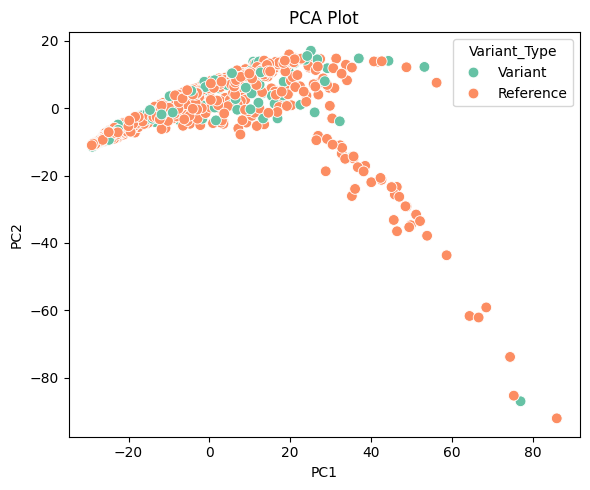

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


# Perform UMAP
# Perform PCA
df = well_profiles_plate_agg.select(pl.col([col for col in well_profiles_plate_agg.columns if not col.startswith("Metadata_")]))

# Standardize the features before PCA
scaler = StandardScaler()
df = pd.DataFrame(scaler.fit_transform(df), columns=df.columns)

pca = PCA(n_components=10)
pca_result = pca.fit_transform(df)

pca_df = pd.DataFrame(pca_result, columns=[f"PC{i+1}" for i in range(pca_result.shape[1])])
pca_df["Metadata_gene_allele"] = well_profiles_plate_agg["Metadata_gene_allele"].to_numpy()
pca_df["Metadata_variant_type"] = well_profiles_plate_agg["Metadata_variant_type"].to_numpy()
pca_df["Metadata_control_type"] = well_profiles_plate_agg["Metadata_control_type"].to_numpy()

# Plot UMAP
fig, ax = plt.subplots(1, 1, figsize=(6, 5))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Metadata_variant_type", palette="Set2", s=60, ax=ax) ## hue=variant_type, 
# texts = []
# for i, label in enumerate(group2_labels):
#     if label in misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"]:
#         texts.append(ax.text(umap_result[i, 0], umap_result[i, 1], label, 
#                      fontsize=6, fontweight='bold', color='black'))
# adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=ax) ## 
ax.set_title("PCA Plot")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend(title="Variant_Type")
plt.tight_layout()
plt.show()

In [11]:
# pca_df[(pca_df["PC1"]>20)&(pca_df["PC2"]<-10)]

In [30]:
# Get PCA loading scores
pca_loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f"PC{i+1}" for i in range(pca.n_components_)],
    index=df.columns
)
pca_loadings.sort_values(by="PC1", ascending=False, inplace=True)
pca_loadings

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
Cells_Texture_DifferenceEntropy_GFP_5_03_256,0.048749,0.010999,0.001420,0.015509,-0.005608,0.020058,-0.003010,0.006234,0.000900,-0.012688
Cells_Texture_DifferenceEntropy_GFP_10_02_256,0.048736,0.011992,0.001433,0.015679,-0.004903,0.018663,-0.000870,0.004024,0.000376,-0.014189
Cells_Texture_DifferenceEntropy_GFP_10_00_256,0.048720,0.011961,0.001350,0.015800,-0.005052,0.018815,-0.000871,0.004021,0.000527,-0.014634
Cells_Texture_DifferenceEntropy_GFP_5_02_256,0.048712,0.010388,0.001740,0.015455,-0.006202,0.021246,-0.005542,0.008468,0.000804,-0.010714
Cells_Texture_DifferenceEntropy_GFP_10_03_256,0.048708,0.012634,0.001074,0.016399,-0.004351,0.017417,0.001067,0.002235,-0.000325,-0.014864
...,...,...,...,...,...,...,...,...,...,...
Nuclei_Texture_InfoMeas1_GFP_5_00_256,-0.047330,0.007157,0.000548,-0.019033,0.012741,-0.019926,-0.018055,0.004970,0.015637,-0.009669
Cytoplasm_Texture_InfoMeas1_GFP_20_00_256,-0.047531,-0.010795,-0.021448,0.010236,0.001831,-0.010461,-0.014925,0.010707,0.027874,-0.013468
Cytoplasm_Texture_InfoMeas1_GFP_20_02_256,-0.047539,-0.010484,-0.022134,0.009834,0.001591,-0.010484,-0.013957,0.010498,0.027378,-0.012068
Cytoplasm_Texture_InfoMeas1_GFP_20_01_256,-0.047596,-0.010859,-0.021841,0.008697,0.004700,-0.015903,-0.014021,0.002313,0.017629,-0.012261


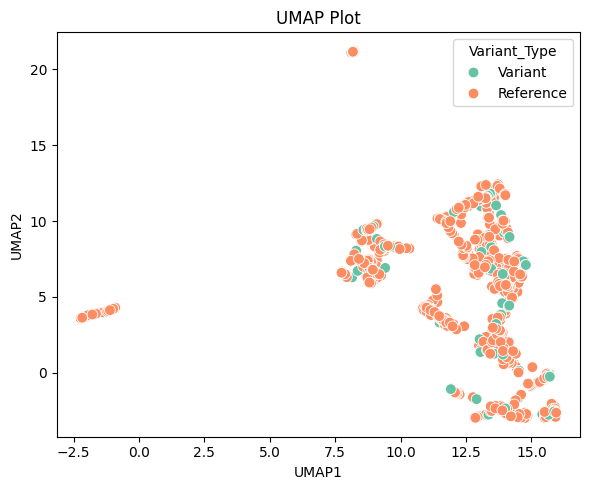

In [ ]:
# from sklearn.preprocessing import StandardScaler

# Perform UMAP
umap_model = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
df = well_profiles_plate_agg.select(pl.col([col for col in well_profiles_plate_agg.columns if not col.startswith("Metadata_")]))

# Standardize the features before PCA
scaler = StandardScaler()
df = pd.DataFrame(scaler.fit_transform(df), columns=df.columns)

umap_result = umap_model.fit_transform(df.to_numpy())
umap_df = pd.DataFrame(umap_result, columns=["UMAP1", "UMAP2"])
umap_df["Metadata_gene_allele"] = well_profiles_plate_agg["Metadata_gene_allele"].to_numpy()
umap_df["Metadata_variant_type"] = well_profiles_plate_agg["Metadata_variant_type"].to_numpy()
umap_df["Metadata_control_type"] = well_profiles_plate_agg["Metadata_control_type"].to_numpy()

# Plot UMAP
fig, ax = plt.subplots(1, 1, figsize=(6, 5))
sns.scatterplot(data=umap_df, x="UMAP1", y="UMAP2", hue="Metadata_variant_type", palette="Set2", s=60, ax=ax) ## hue=variant_type, 
# texts = []
# for i, label in enumerate(group2_labels):
#     if label in misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"]:
#         texts.append(ax.text(umap_result[i, 0], umap_result[i, 1], label, 
#                      fontsize=6, fontweight='bold', color='black'))
# adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=ax) ## 
ax.set_title("UMAP Plot")
ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")
ax.legend(title="Variant_Type")
plt.tight_layout()
plt.show()

In [45]:
umap_df[umap_df["UMAP1"]<5]

,UMAP1,UMAP2,Metadata_gene_allele,Metadata_variant_type,Metadata_control_type
85,-5.408559,2.401598,BCL10,Variant,Allele
86,-5.443964,2.436691,BCL10_Leu8Leu,Reference,Allele
158,-4.339586,1.454342,DES,Variant,Allele
159,-4.822032,1.871822,DES_Ala135Val,Reference,Allele
160,-4.325285,1.440421,DES_Ala213Val,Reference,Allele
161,-4.478699,1.580750,DES_Ala237Thr,Reference,Allele
165,-5.196033,2.195946,DES_Ala397Thr,Reference,Allele
166,-4.363954,1.471305,DES_Arg127Pro,Reference,Allele
167,-4.976421,2.001152,DES_Arg150Gln,Reference,Allele
168,-4.243656,1.365429,DES_Arg16Cys,Reference,Allele


In [48]:
umap_df[(umap_df["UMAP1"]>5)&(umap_df["UMAP2"]>15)]

,UMAP1,UMAP2,Metadata_gene_allele,Metadata_variant_type,Metadata_control_type
267,10.670685,16.623707,GATA2_Cys373Arg,Reference,Allele
482,10.698064,16.720434,NMNAT1,Variant,Allele
483,10.612729,16.633656,NMNAT1_Arg207Trp,Reference,Allele
485,10.680852,16.699604,NMNAT1_Asn273Asp,Reference,Allele
487,10.589437,16.647108,NMNAT1_Leu153Val,Reference,Allele
488,10.634657,16.653881,NMNAT1_Ser255Asn,Reference,Allele
489,10.671806,16.605488,ORC6,Variant,Allele
490,10.619808,16.666800,ORC6_Tyr232Ser,Reference,Allele
552,10.573025,16.600382,PLA2G6,Variant,Allele
670,10.656266,16.667801,SNIP1,Variant,Allele


## Co-localization patterns

In [13]:
## Select colocalization metrics between meaningful channels
## Select columns that contain "Correlation" but not "Brightfield", brightfield doesn't provide useful information here
colocal_cols = [col for col in well_profiles.columns if "Correlation" in col and "Brightfield" not in col]
colocal_col_cat = set(["_".join(col.split('_')[1:3]) for col in colocal_cols])
print(colocal_col_cat)

colocal_col_dict = defaultdict(list)
for col in colocal_cols:
    colocal_col_dict["_".join(col.split('_')[1:3])].append(col)
# colocal_col_dict

{'Correlation_Overlap', 'Correlation_Manders', 'Correlation_RWC', 'Texture_Correlation', 'Correlation_K', 'Correlation_Costes', 'Correlation_Correlation'}


## WT gene well profiles

In [14]:
well_profiles_wt = well_profiles.filter(
    ~pl.col("Metadata_gene_allele").str.contains("_")
).sort(
    pl.col(["Metadata_gene_allele","Metadata_Plate"])
)
well_profiles_wt

Metadata_Plate,Metadata_Well,Metadata_gene_allele,Cytoplasm_Correlation_Correlation_AGP_GFP,Cytoplasm_Correlation_Correlation_Brightfield_GFP,Cytoplasm_Correlation_Correlation_Brightfield_H_GFP,Cytoplasm_Correlation_Correlation_Brightfield_L_GFP,Cytoplasm_Correlation_Correlation_DNA_GFP,Cytoplasm_Correlation_Correlation_GFP_Mito,Cytoplasm_Correlation_Costes_AGP_GFP,Cytoplasm_Correlation_Costes_Brightfield_GFP,Cytoplasm_Correlation_Costes_Brightfield_H_GFP,Cytoplasm_Correlation_Costes_Brightfield_L_GFP,Cytoplasm_Correlation_Costes_DNA_GFP,Cytoplasm_Correlation_Costes_GFP_AGP,Cytoplasm_Correlation_Costes_GFP_Brightfield,Cytoplasm_Correlation_Costes_GFP_Brightfield_H,Cytoplasm_Correlation_Costes_GFP_Brightfield_L,Cytoplasm_Correlation_Costes_GFP_DNA,Cytoplasm_Correlation_Costes_GFP_Mito,Cytoplasm_Correlation_Costes_Mito_GFP,Cytoplasm_Correlation_K_AGP_GFP,Cytoplasm_Correlation_K_Brightfield_GFP,Cytoplasm_Correlation_K_Brightfield_H_GFP,Cytoplasm_Correlation_K_Brightfield_L_GFP,Cytoplasm_Correlation_K_DNA_GFP,Cytoplasm_Correlation_K_GFP_AGP,Cytoplasm_Correlation_K_GFP_Brightfield,Cytoplasm_Correlation_K_GFP_Brightfield_H,Cytoplasm_Correlation_K_GFP_Brightfield_L,Cytoplasm_Correlation_K_GFP_DNA,Cytoplasm_Correlation_K_GFP_Mito,Cytoplasm_Correlation_K_Mito_GFP,Cytoplasm_Correlation_Manders_AGP_GFP,Cytoplasm_Correlation_Manders_Brightfield_GFP,Cytoplasm_Correlation_Manders_Brightfield_H_GFP,Cytoplasm_Correlation_Manders_Brightfield_L_GFP,…,Nuclei_Texture_SumAverage_GFP_5_03_256,Nuclei_Texture_SumEntropy_GFP_10_00_256,Nuclei_Texture_SumEntropy_GFP_10_01_256,Nuclei_Texture_SumEntropy_GFP_10_02_256,Nuclei_Texture_SumEntropy_GFP_10_03_256,Nuclei_Texture_SumEntropy_GFP_20_00_256,Nuclei_Texture_SumEntropy_GFP_20_01_256,Nuclei_Texture_SumEntropy_GFP_20_02_256,Nuclei_Texture_SumEntropy_GFP_20_03_256,Nuclei_Texture_SumEntropy_GFP_5_00_256,Nuclei_Texture_SumEntropy_GFP_5_01_256,Nuclei_Texture_SumEntropy_GFP_5_02_256,Nuclei_Texture_SumEntropy_GFP_5_03_256,Nuclei_Texture_SumVariance_GFP_10_00_256,Nuclei_Texture_SumVariance_GFP_10_01_256,Nuclei_Texture_SumVariance_GFP_10_02_256,Nuclei_Texture_SumVariance_GFP_10_03_256,Nuclei_Texture_SumVariance_GFP_20_00_256,Nuclei_Texture_SumVariance_GFP_20_01_256,Nuclei_Texture_SumVariance_GFP_20_02_256,Nuclei_Texture_SumVariance_GFP_20_03_256,Nuclei_Texture_SumVariance_GFP_5_00_256,Nuclei_Texture_SumVariance_GFP_5_01_256,Nuclei_Texture_SumVariance_GFP_5_02_256,Nuclei_Texture_SumVariance_GFP_5_03_256,Nuclei_Texture_Variance_GFP_10_00_256,Nuclei_Texture_Variance_GFP_10_01_256,Nuclei_Texture_Variance_GFP_10_02_256,Nuclei_Texture_Variance_GFP_10_03_256,Nuclei_Texture_Variance_GFP_20_00_256,Nuclei_Texture_Variance_GFP_20_01_256,Nuclei_Texture_Variance_GFP_20_02_256,Nuclei_Texture_Variance_GFP_20_03_256,Nuclei_Texture_Variance_GFP_5_00_256,Nuclei_Texture_Variance_GFP_5_01_256,Nuclei_Texture_Variance_GFP_5_02_256,Nuclei_Texture_Variance_GFP_5_03_256
str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""2024_01_19_B7A…","""B08""","""ACACB""",0.209386,-0.102414,-0.100254,-0.10583,0.218471,0.55103,0.872907,0.009793,0.000829,0.078723,0.916885,1.0,1.0,0.51685,1.0,0.567537,1.0,1.0,0.135624,0.09144,0.092116,0.091375,0.690829,6.608265,10.687915,10.700838,10.70103,1.233437,17.793319,0.048558,1.0,1.0,1.0,1.0,…,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""2024_01_22_B7A…","""B08""","""ACACB""",0.20117,-0.09214,-0.086157,-0.080617,0.185177,0.527714,0.873305,0.0,0.0,0.0,0.958477,1.0,0.0,0.0,0.0,0.665684,1.0,0.998969,0.363056,0.105012,0.104847,0.104458,0.763093,2.307217,9.258984,9.228502,9.441518,1.229213,21.36025,0.040013,1.0,1.0,1.0,1.0,…,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,

### Co-localization patterns

                                                mean       std  Corr_cat
index                                                                   
Nuclei_Correlation_Correlation_GFP_Mito     0.395787  0.212546  GFP_Mito
Cytoplasm_Correlation_Correlation_GFP_Mito  0.612596  0.194620  GFP_Mito
Cells_Correlation_Correlation_GFP_Mito      0.560901  0.180248  GFP_Mito
Nuclei_Correlation_Correlation_DNA_GFP     -0.131063  0.451859   DNA_GFP
Cytoplasm_Correlation_Correlation_DNA_GFP   0.283727  0.159057   DNA_GFP
Cells_Correlation_Correlation_DNA_GFP       0.197164  0.355795   DNA_GFP
Nuclei_Correlation_Correlation_AGP_GFP      0.199590  0.259077   AGP_GFP
Cytoplasm_Correlation_Correlation_AGP_GFP   0.219036  0.120225   AGP_GFP
Cells_Correlation_Correlation_AGP_GFP       0.192089  0.129070   AGP_GFP


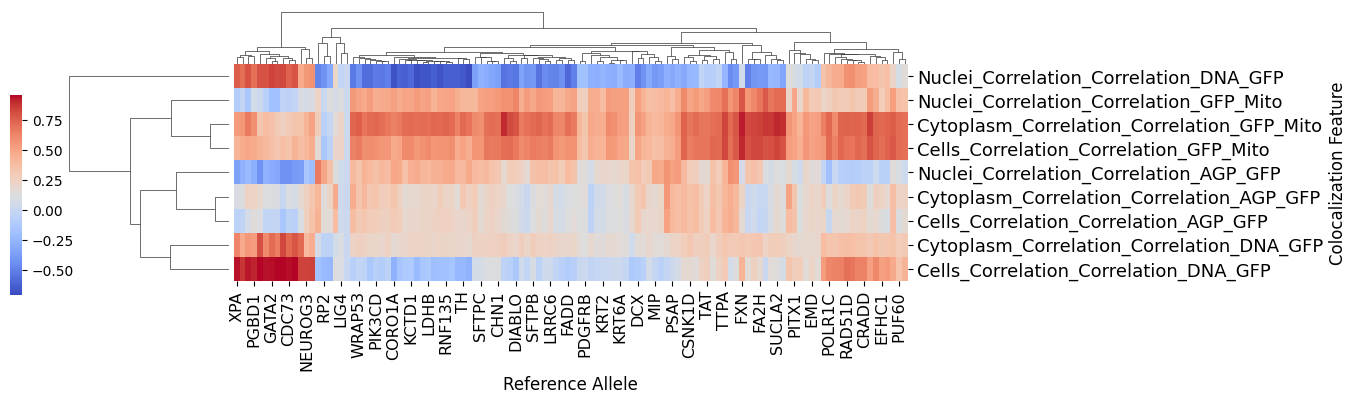

In [41]:
well_profiles_wt_gene = well_profiles_wt.group_by("Metadata_gene_allele").agg(
    pl.col(col).median().alias(col)
    for col in colocal_cols
).select(["Metadata_gene_allele"] + colocal_cols).to_pandas().set_index("Metadata_gene_allele")

## Calculate mean and standard deviation for each column
column_stats = well_profiles_wt_gene[colocal_col_dict["Correlation_Correlation"]].agg(['mean', 'std']).T.reset_index()
column_stats["Corr_cat"] = column_stats["index"].apply(lambda x: "_".join(x.split("_")[-2:]))
## Sort columns by the sum of mean and std in descending order
sorted_columns = column_stats.sort_values(by=["Corr_cat","index"], ascending=False)
sorted_columns.set_index("index", inplace=True)
print(sorted_columns)

# sorted_columns.loc[colocal_col_dict["Correlation_Correlation"]]
# sorted_columns.loc[colocal_col_dict["Correlation_Costes"]] ## means nearly all to 1, meaningless here
# sorted_columns.loc[colocal_col_dict["Correlation_RWC"]] ## means nearly all to 1, meaningless here
# sorted_columns.loc[colocal_col_dict["Correlation_Manders"]] ## means nearly all to 1, meaningless here

# ## filter out corr columns with mean <= 1
# sorted_columns = sorted_columns[sorted_columns["mean"] > 1]
# display(sorted_columns)

g = sns.clustermap(well_profiles_wt_gene[sorted_columns.index].T, figsize=(12, 4), cmap="coolwarm", 
cbar_pos=(-.03, .25, .01, .5), #xticklabels=2, 
row_cluster=True, col_cluster=True) ## , "viridis", z_score=0, standard_scale=0, 
rot_xticks = plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90, ha="center", fontsize=11.5)
rot_xticks = plt.setp(g.ax_heatmap.get_yticklabels(), rotation=0, ha="left", fontsize=13)
rot_xticks = g.ax_heatmap.set_xlabel("Reference Allele", fontsize=12)
rot_xticks = g.ax_heatmap.set_ylabel("Colocalization Feature", fontsize=12)
# g.fig.suptitle("Mislocalized Variants' Reference Alleles: Pearson's Correlation between Channels", y=1.) 

## Well Profiles Visualization

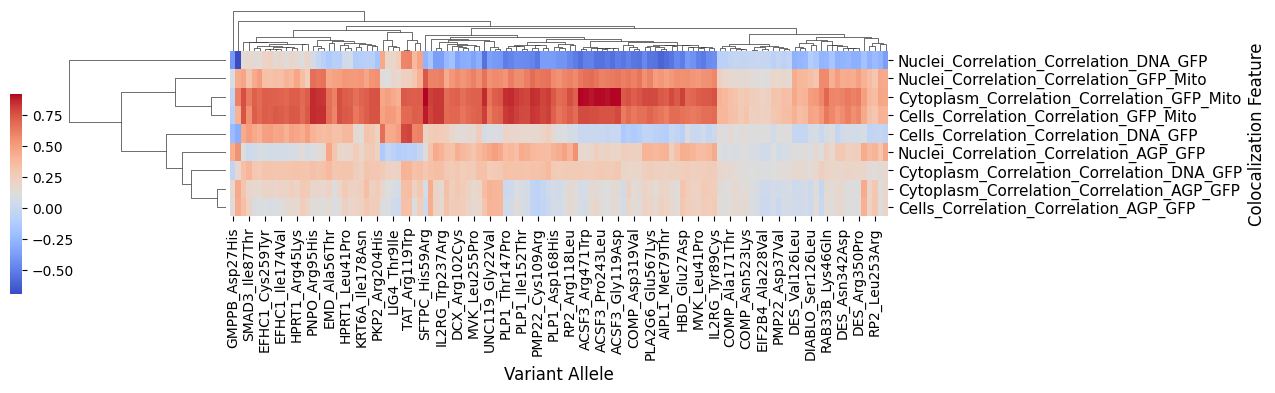

In [43]:
well_profiles_var = well_profiles.filter(
    pl.col("Metadata_gene_allele").str.contains("_")
).sort(
    pl.col(["Metadata_gene_allele","Metadata_Plate"])
)

well_profiles_var_allele = well_profiles_var.group_by(["Metadata_gene_allele"]).agg(
    pl.col(col).median().alias(col)
        for col in colocal_cols
).unique().select(["Metadata_gene_allele"] + colocal_cols).to_pandas().set_index("Metadata_gene_allele")

# Calculate mean and standard deviation for each column
column_stats = well_profiles_var_allele[colocal_col_dict["Correlation_Correlation"]].agg(['mean', 'std']).T
# Sort columns by the sum of mean and std in descending order
# sorted_columns = column_stats.sort_values(by=["mean", "std"], ascending=False)

# display(well_profiles_var_allele.loc[sig_misloc_alleles, sorted_columns.index])

# sns.set(font_scale=.8)
g = sns.clustermap(well_profiles_var_allele.loc[sig_misloc_alleles, sorted_columns.index].T, figsize=(12, 4), cmap="coolwarm", 
cbar_pos=(-.03, .25, .01, .5), #xticklabels=2, 
row_cluster=True, col_cluster=True) ## , "viridis", z_score=0, standard_scale=0, 
rot_xticks = plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90, ha="center", fontsize=10)
rot_xticks = plt.setp(g.ax_heatmap.get_yticklabels(), rotation=0, ha="left", fontsize=11)
rot_xticks = g.ax_heatmap.set_xlabel("Variant Allele", fontsize=12)
rot_xticks = g.ax_heatmap.set_ylabel("Colocalization Feature", fontsize=12)


# gfp_cols = [col for col in well_profiles_merge_plate.columns if "GFP" in col]
# well_profiles_merge_plate = well_profiles_merge_plate.select(
#     [col for col in gfp_cols if well_profiles_merge_plate[col].std() > 2] + ["Metadata_gene_allele"]
# )

In [49]:
# display(well_profiles_var_allele[sorted_columns.index])
# display(well_profiles_wt_gene[sorted_columns.index])

well_profiles_var_allele_regroup = well_profiles_var_allele.loc[sig_misloc_alleles,].reset_index()
well_profiles_var_allele_regroup["Gene"] = well_profiles_var_allele_regroup["Metadata_gene_allele"].apply(lambda x: x.split("_")[0])

misloc_scores = pd.DataFrame()
for gene, group in well_profiles_var_allele_regroup.groupby("Gene"):
    # print(gene)
    # display(group)
    group = group.set_index("Metadata_gene_allele")
    group = group - well_profiles_wt_gene.loc[gene]
    misloc_scores = pd.concat([misloc_scores, group], axis=0)

# misloc_scores.columns = [col+"_var-wt" for col in misloc_scores.columns]
misloc_scores

,Cells_Correlation_Correlation_AGP_GFP,Cells_Correlation_Correlation_DNA_GFP,Cells_Correlation_Correlation_GFP_Mito,Cells_Correlation_Costes_AGP_GFP,Cells_Correlation_Costes_DNA_GFP,Cells_Correlation_Costes_GFP_AGP,Cells_Correlation_Costes_GFP_DNA,Cells_Correlation_Costes_GFP_Mito,Cells_Correlation_Costes_Mito_GFP,Cells_Correlation_K_AGP_GFP,...,Nuclei_Texture_Correlation_GFP_10_02_256,Nuclei_Texture_Correlation_GFP_10_03_256,Nuclei_Texture_Correlation_GFP_20_00_256,Nuclei_Texture_Correlation_GFP_20_01_256,Nuclei_Texture_Correlation_GFP_20_02_256,Nuclei_Texture_Correlation_GFP_20_03_256,Nuclei_Texture_Correlation_GFP_5_00_256,Nuclei_Texture_Correlation_GFP_5_01_256,Nuclei_Texture_Correlation_GFP_5_02_256,Nuclei_Texture_Correlation_GFP_5_03_256
Metadata_gene_allele,,,,,,,,,,,,,,,,,,,,,
ACSF3_Thr358Ile,-0.198333,-0.339428,0.233743,-0.007262,-0.006532,0.000000,0.355117,0.000000,0.000101,-0.081000,...,-0.517312,-0.504952,0.000000,0.000000,0.000000,0.000000,-0.420288,-0.473053,-0.431365,-0.493689
ACSF3_Ser431Tyr,-0.301760,0.099223,-0.024178,-0.224049,-0.035734,-0.030480,-0.171261,0.000000,0.000031,-0.205888,...,0.451776,0.479928,1.000000,1.000000,1.000000,1.000000,0.364448,0.422510,0.372056,0.420498
ACSF3_Asp457Asn,-0.321329,-0.348617,0.241134,-0.005197,-0.003620,0.000000,0.064869,-0.000177,-0.000763,-0.082921,...,-0.547559,-0.521004,0.000000,0.000000,0.000000,0.000000,-0.495091,-0.520600,-0.515182,-0.541976
ACSF3_Pro243Leu,-0.269969,-0.346456,0.217324,-0.011654,-0.005864,0.000000,0.033845,0.000000,0.000066,-0.102865,...,-0.517450,-0.519294,0.000000,0.000000,0.000000,0.000000,-0.387990,-0.493091,-0.416555,-0.451129
ACSF3_Met266Val,-0.232930,-0.348781,0.216314,-0.014912,-0.005074,0.000000,-0.010911,0.000000,0.000150,-0.139852,...,-0.502904,-0.490095,0.000000,0.000000,0.000000,0.000000,-0.400544,-0.472104,-0.419861,-0.448663
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TH_Glu250Gln,-0.038152,0.341609,-0.185059,-0.344773,-0.199593,-0.156528,-0.706247,0.000000,-0.000043,-1.546976,...,0.926591,1.011336,1.046677,1.103011,1.023487,1.097005,0.697200,0.839464,0.711625,0.840803
TTPA_Gly246Arg,-0.008710,-0.053392,-0.040964,0.000000,0.000319,0.000000,0.061269,0.000104,0.000000,-2.499226,...,-0.020095,-0.004407,0.025901,0.094588,0.016992,0.061874,-0.086938,-0.042438,-0.080490,-0.064098
UNC119_Gly22Val,0.025281,-0.391414,-0.162012,0.000000,-0.000209,0.000000,-0.246847,-0.002621,-0.000193,1.069590,...,-0.066738,-0.087976,-0.032702,-0.096823,-0.022201,-0.117062,-0.046942,-0.082244,0.033964,0.023552


In [92]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import numpy as np

silhouette_scores = []
cluster_range = range(2, 10)  # Trying clusters from 2 to 9
df = misloc_scores[sorted_columns.index] #.dropna(axis=1).copy()

for k in cluster_range:
    clustering = AgglomerativeClustering(n_clusters=k, linkage='ward')
    labels = clustering.fit_predict(df)
    score = silhouette_score(df, labels)
    silhouette_scores.append(score)
    print(f"Clusters: {k}, Silhouette Score: {score:.4f}")

# Select the number of clusters that has the highest silhouette score
optimal_clusters = cluster_range[np.argmax(silhouette_scores)]
print(f"Optimal number of clusters determined: {optimal_clusters}")

Clusters: 2, Silhouette Score: 0.4779
Clusters: 3, Silhouette Score: 0.3462
Clusters: 4, Silhouette Score: 0.3582
Clusters: 5, Silhouette Score: 0.3363
Clusters: 6, Silhouette Score: 0.3184
Clusters: 7, Silhouette Score: 0.2946
Clusters: 8, Silhouette Score: 0.3336
Clusters: 9, Silhouette Score: 0.3497
Optimal number of clusters determined: 2


In [93]:
# ----------------------------
# 3. Perform Hierarchical Clustering with the Optimal Cluster Count
# ----------------------------
agg_model = AgglomerativeClustering(n_clusters=4, linkage='ward')
df.loc[:,'cluster'] = agg_model.fit_predict(df)

/tmp/ipykernel_326136/3202266153.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.loc[:,'cluster'] = agg_model.fit_predict(df)


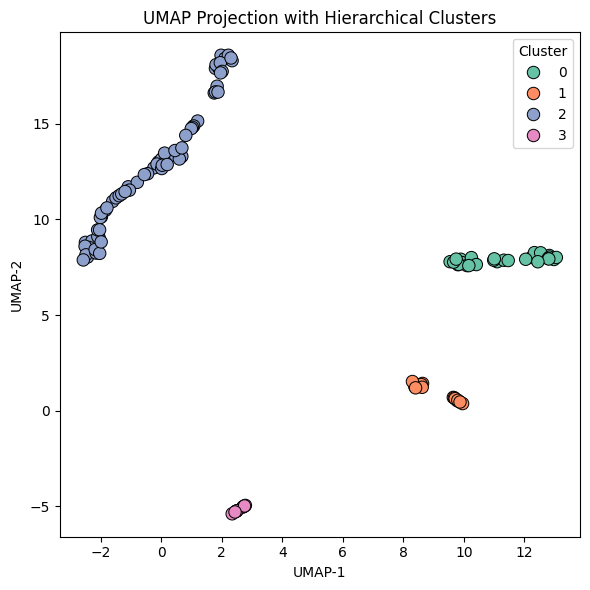

In [114]:
# ----------------------------
# 4. Compute UMAP Projection and Plot the Clusters
# ----------------------------
umap_reducer = umap.UMAP(random_state=42)
embedding = umap_reducer.fit_transform(df)
df.loc[:,'UMAP-1'] = embedding[:, 0]
df.loc[:,'UMAP-2'] = embedding[:, 1]

plt.figure(figsize=(6, 6))
sns.scatterplot(x='UMAP-1', y='UMAP-2', hue='cluster', 
                palette='Set2', data=df, s=80, edgecolor='k')
plt.title("UMAP Projection with Hierarchical Clusters")
plt.xlabel("UMAP-1")
plt.ylabel("UMAP-2")
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

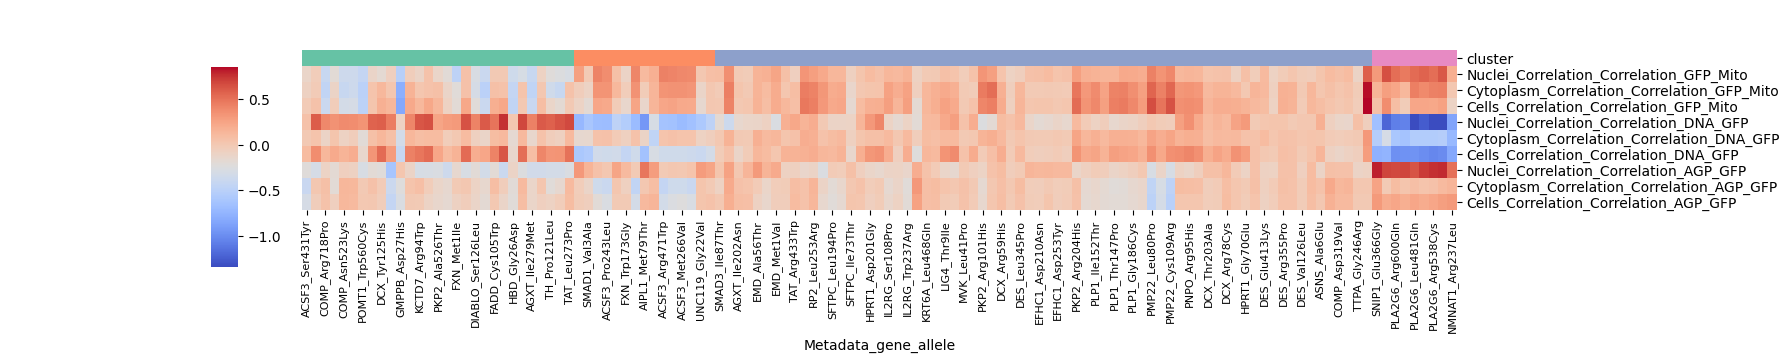

In [113]:
# df = df.set_index("Group2")
unique_clusters = np.sort(df['cluster'].unique())
palette = sns.color_palette("Set2", len(unique_clusters))
lut = dict(zip(unique_clusters, palette))
row_colors = df['cluster'].map(lut)

# Create the clustermap. We use only the original features.
# The row_colors argument is used to annotate the rows based on our clusters.
g = sns.clustermap(df.sort_values(by="cluster")[sorted_columns.index].T,
                   col_colors=row_colors,
                   metric="euclidean",
                   method="ward",
                   cmap="coolwarm",
                   cbar_pos=(.12, .32, .015, .5),
                   figsize=(18, 4),
                   row_cluster=False,
                   colors_ratio=0.08,
                   col_cluster=False)
rot_xticks = plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90, ha="center", fontsize=8)

# Optionally, add a legend for the row_colors
# for label in unique_clusters:
#     g.ax_row_dendrogram.bar(1, 0, color=lut[label],
#                             label=f'Cluster {label}', linewidth=0)
# g.ax_row_dendrogram.legend(loc="upper right", ncol=1, title="Cluster Labels")
# plt.setp(g.ax_heatmap.get_yticklabels(), rotation=0, fontsize=6)
# plt.setp(g.ax_heatmap.set_ylabel(""), rotation=0, fontsize=6)
# plt.suptitle("Seaborn Clustermap with Assigned Clusters", y=1.05)
# plt.show()

In [ ]:
g = sns.clustermap(misloc_scores.loc[sig_misloc_alleles,sorted_columns.index].T, figsize=(12, 4), cmap="coolwarm", 
cbar_pos=(-.03, .25, .01, .5), #xticklabels=2, 
row_cluster=True, col_cluster=True) ## , "viridis", z_score=0, standard_scale=0, 
rot_xticks = plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90, ha="center", fontsize=10)
rot_xticks = plt.setp(g.ax_heatmap.get_yticklabels(), rotation=0, ha="left", fontsize=11)
rot_xticks = g.ax_heatmap.set_xlabel("Variant Allele", fontsize=12)
rot_xticks = g.ax_heatmap.set_ylabel("Colocalization Feature", fontsize=12)

In [59]:
[idx for idx in misloc_scores.index if "PLA2G6" in idx]

['PLA2G6_Glu567Lys',
 'PLA2G6_Arg600Gln',
 'PLA2G6_Leu481Gln',
 'PLA2G6_Val310Glu',
 'PLA2G6_Thr585Ile',
 'PLA2G6_Arg538Cys']

In [ ]:
# Perform UMAP
umap_model = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
umap_result = umap_model.fit_transform(misloc_scores.loc[sig_misloc_alleles, sorted_columns.index])
umap_df = pd.DataFrame(umap_result, columns=["UMAP1", "UMAP2"])
umap_df["Metadata_gene_allele"] = sig_misloc_alleles

/tmp/ipykernel_151077/643913833.py:3: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(x=umap_result[:, 0], y=umap_result[:, 1], palette="Set2", s=60, ax=ax) ## hue=variant_type,
/tmp/ipykernel_151077/643913833.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title="Variant_Type")


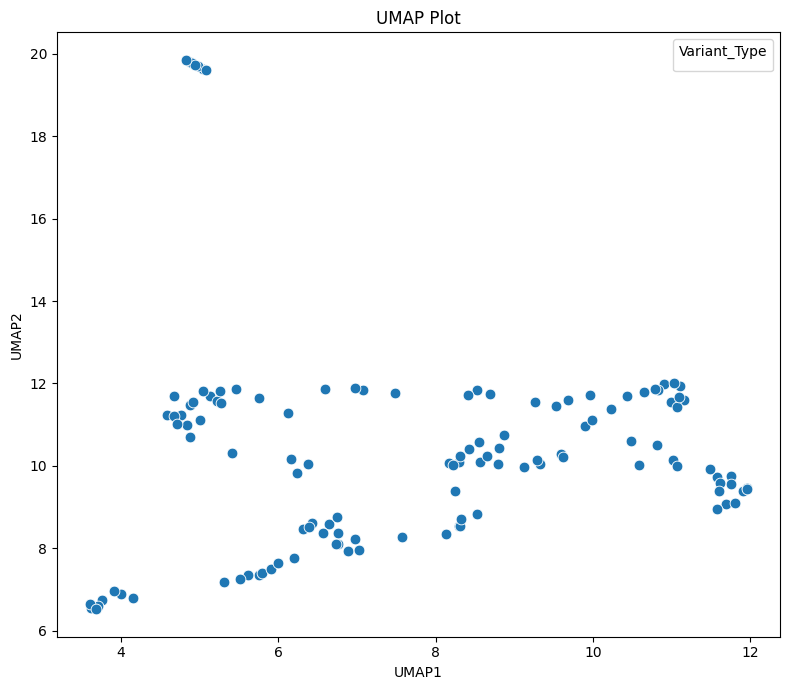

In [62]:
# Plot UMAP
fig, ax = plt.subplots(1, 1, figsize=(8, 7))
sns.scatterplot(x=umap_result[:, 0], y=umap_result[:, 1], palette="Set2", s=60, ax=ax) ## hue=variant_type, 
# texts = []
# for i, label in enumerate(group2_labels):
#     if label in misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"]:
#         texts.append(ax.text(umap_result[i, 0], umap_result[i, 1], label, 
#                      fontsize=6, fontweight='bold', color='black'))
# adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=ax) ## 
ax.set_title("UMAP Plot")
ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")
ax.legend(title="Variant_Type")
plt.tight_layout()
plt.show()

In [20]:
local_wtvar.filter(pl.col("allele_0").str.contains("ACSF3")).sort(pl.col("allele_0","Batch"))#.select(pl.col("allele_0")).unique()

Classifier_type,allele_0,Allele_set,Batch,AUROC_thresh,AUROC_mean,trainsize_0_mean,testsize_0_mean,trainsize_1_mean,testsize_1_mean,Training_imbalance_mean,mislocalized
str,str,str,str,f64,f64,f64,f64,f64,f64,f64,i32
"""localization""","""ACSF3_Ala197Th…","""A1P1""","""B7""",0.71418,0.967056,497.25,165.75,806.25,268.75,1.624526,1
"""localization""","""ACSF3_Arg10Trp…","""A1P1""","""B7""",0.71418,0.953108,1461.0,487.0,806.25,268.75,1.812773,1
"""localization""","""ACSF3_Arg471Tr…","""A1P1""","""B7""",0.71418,0.975904,807.0,269.0,806.25,268.75,1.043461,1
"""localization""","""ACSF3_Arg471Tr…","""A1P1""","""B8""",0.861392,0.95188,276.75,92.25,137.25,45.75,2.026597,1
"""localization""","""ACSF3_Arg558Tr…","""A1P1""","""B7""",0.71418,0.972141,483.75,161.25,806.25,268.75,1.679772,1
"""localization""","""ACSF3_Arg558Tr…","""A1P1""","""B8""",0.861392,0.959306,144.75,48.25,137.25,45.75,1.157665,1
"""localization""","""ACSF3_Asp457As…","""A1P1""","""B7""",0.71418,0.975797,432.75,144.25,806.25,268.75,1.863958,1
"""localization""","""ACSF3_Asp457As…","""A1P1""","""B8""",0.861392,0.957957,203.25,67.75,137.25,45.75,1.487355,1
"""localization""","""ACSF3_Glu359Ly…","""A1P1""","""B7""",0.71418,0.975252,933.0,311.0,806.25,268.75,1.157019,1


In [64]:
umap_df[umap_df["UMAP2"]>18]["Metadata_gene_allele"].to_list()

['ACSF3_Arg471Trp',
 'ACSF3_Arg558Trp',
 'ACSF3_Asp457Asn',
 'ACSF3_Thr358Ile',
 'ACSF3_Met266Val',
 'ACSF3_Gly119Asp',
 'ACSF3_Pro243Leu']

In [ ]:
inputs_dir = "../../../../3_integrated_assay_results/1_inputs"
ai_scores = pl.read_csv(f"{inputs_dir}/ai_pred_struc_scores.tsv", separator="\t", infer_schema_length=10000)

ai_acsf3 = ai_scores.filter(pl.col("symbol")=="ACSF3").with_columns(
    pl.concat_str([pl.col("symbol"), pl.col("aa_change")], separator="_").alias("variant")
).filter(pl.col("symbol")=="ACSF3")

ai_acsf3.with_columns(
    pl.when(pl.col("variant").is_in(['ACSF3_Arg471Trp',
        'ACSF3_Arg558Trp',
        'ACSF3_Asp457Asn',
        'ACSF3_Thr358Ile',
        'ACSF3_Met266Val',
        'ACSF3_Gly119Asp',
        'ACSF3_Pro243Leu']))
    .then(pl.lit("1_Mislocalized"))
    .otherwise(pl.lit("2_Non-Mislocalized"))
    .alias("Misloc")
)

In [ ]:
local_wtvar.filter(pl.col("allele_0").str.contains("PLA2G6")).sort(pl.col("AUROC_mean"))
# [al for al in all_alleles if "PLA2G6" in al]

Classifier_type,allele_0,Allele_set,Batch,AUROC_thresh,AUROC_mean,trainsize_0_mean,testsize_0_mean,trainsize_1_mean,testsize_1_mean,Training_imbalance_mean,mislocalized
str,str,str,str,f64,f64,f64,f64,f64,f64,f64,i32
"""localization""","""PLA2G6_Leu481G…","""A1P3""","""B8""",0.861392,0.975955,80.666667,40.333333,100.666667,50.333333,1.26084,1
"""localization""","""PLA2G6_Thr585I…","""A1P3""","""B8""",0.861392,0.980062,122.0,61.0,100.666667,50.333333,1.202233,1
"""localization""","""PLA2G6_Arg600G…","""A1P3""","""B8""",0.861392,0.983921,146.666667,73.333333,100.666667,50.333333,1.457242,1
"""localization""","""PLA2G6_Glu567L…","""A1P3""","""B8""",0.861392,0.988764,72.0,36.0,100.666667,50.333333,1.40098,1
"""localization""","""PLA2G6_Arg538C…","""A1P3""","""B7""",0.71418,0.991076,628.5,209.5,341.25,113.75,1.886324,1
"""localization""","""PLA2G6_Val310G…","""A1P3""","""B7""",0.71418,0.993679,462.75,154.25,341.25,113.75,1.457059,1
"""localization""","""PLA2G6_Leu481G…","""A1P3""","""B7""",0.71418,0.99416,408.75,136.25,341.25,113.75,1.29248,1
"""localization""","""PLA2G6_Glu567L…","""A1P3""","""B7""",0.71418,0.994567,295.5,98.5,341.25,113.75,1.159498,1
"""localization""","""PLA2G6_Arg600G…","""A1P3""","""B7""",0.71418,0.994797,486.75,162.25,341.25,113.75,1.440416,1
